In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df_raw = pd.read_excel(file_name)

print("Rows and columns:", df_raw.shape)
display(df_raw.head())


Saving Workforce_Sustainability_RF_Highest_Accuracy_Benchmark_46_Columns.xlsx to Workforce_Sustainability_RF_Highest_Accuracy_Benchmark_46_Columns.xlsx
Rows and columns: (36869, 46)


,Data_Status,Employee_ID,Financial_Year,Age,Age_Band,Gender,Region,Employee_Category,Job_Function,Grade_Band,...,Reported_Employee_Headcount,Reported_Learning_Hours_Total,Reported_Average_Learning_Hours_Per_Employee,Reported_Training_Expense_INR_Crore,Reported_Training_Expense_Per_Employee_INR,Reported_Engagement_Vibes_Score,Reported_Women_Workforce_Pct,Reported_Employee_Expense_INR_Crore,Reported_Branch_Count,Data_Provenance_Note
0,Synthetic KPI-aligned RF benchmark,SYN000001,FY2024,36,30-50,Male,East,Non-supervisory,Customer service,G1-G3,...,NaN,6654452,31.16,421,19708,NaN,NaN,NaN,NaN,Synthetic benchmark: exit flag engineered usin...
1,Synthetic KPI-aligned RF benchmark,SYN000001,FY2025,37,30-50,Male,East,Non-supervisory,Customer service,G1-G3,...,214521.0,12495372,58.25,473,22035,NaN,26.14,23900.5,NaN,Synthetic benchmark: exit flag engineered usin...
2,Synthetic KPI-aligned RF benchmark,SYN000001,FY2026,38,30-50,Male,East,Non-supervisory,Customer service,G1-G3,...,211178.0,13653941,64.66,363,17212,86.0,26.60,26050.0,9689.0,Synthetic benchmark: exit flag engineered usin...
3,Synthetic KPI-aligned RF benchmark,SYN000002,FY2024,48,30-50,Female,North,Non-supervisory,Branch banking,G1-G3,...,NaN,6654452,31.16,421,19708,NaN,NaN,NaN,NaN,Synthetic benchmark: exit flag engineered usin...
4,Synthetic KPI-aligned RF benchmark,SYN000003,FY2024,50,30-50,Male,North,Non-supervisory,Operations,G1-G3,...,NaN,6654452,31.16,421,19708,NaN,NaN,NaN,NaN,Synthetic benchmark: exit flag engineered usin...


In [133]:

print("Dataset shape:", df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nStatistical summary:")
display(df_raw.describe(include="all").T)


Dataset shape: (36869, 46)

Column names:
['Data_Status', 'Employee_ID', 'Financial_Year', 'Age', 'Age_Band', 'Gender', 'Region', 'Employee_Category', 'Job_Function', 'Grade_Band', 'Education', 'Tenure_Years_at_FY_Start', 'Annual_Base_Pay_INR_Lakh', 'Learning_Hours', 'Training_Expense_INR', 'Learning_Assessment_Pre_Score', 'Learning_Assessment_Post_Score', 'Desk_Readiness_Flag', 'On_Job_Application_Flag', 'Engagement_Score_Synthetic', 'Survey_Eligible_Flag', 'Survey_Responded_Flag', 'Talent_Review_Eligible_Flag', 'Talent_Reviewed_Flag', 'Internal_Hire_Flag', 'Total_Hire_Events_Synthetic', 'Employee_Exit_Flag', 'Exit_Reason_Synthetic', 'Branch_Assignment_ID', 'Branch_Count_Synthetic_Year_Total', 'Branches_Opened_Synthetic_Year_Total', 'Region_Branch_Count_Synthetic', 'Region_Branches_Opened_Synthetic', 'RBI_HDFC_Office_Opening_Count', 'RBI_Office_Data_Source', 'Reported_Employee_Turnover_Rate_Pct', 'Reported_Employee_Headcount', 'Reported_Learning_Hours_Total', 'Reported_Average_Learnin

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Data_Status,36869,1,Synthetic KPI-aligned RF benchmark,36869,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employee_ID,36869,15000,SYN015000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Financial_Year,36869,3,FY2024,15000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,36869.0,NaN,NaN,NaN,33.308226,7.053753,21.0,28.0,33.0,38.0,59.0
Age_Band,36869,3,30-50,25197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,36869,3,Male,25417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,36869,5,West,11293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employee_Category,36869,4,Non-supervisory,25522,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Function,36869,7,Branch banking,10085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade_Band,36869,4,G1-G3,25522,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [134]:

# Exact duplicate rows
print("Exact duplicate rows:", df_raw.duplicated().sum())

# Missing values
missing = pd.DataFrame({
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percentage": (
        df_raw.isna().mean() * 100
    ).round(2)
}).sort_values("Missing_Percentage", ascending=False)

display(missing)

# Unique values for selected columns
for col in [
    "Financial_Year", "Gender", "Region",
    "Employee_Category", "Data_Status"
]:
    print(f"\n{col}:")
    print(df_raw[col].value_counts(dropna=False))


Exact duplicate rows: 0


,Missing_Count,Missing_Percentage
RBI_HDFC_Office_Opening_Count,36869,100.00
Reported_Engagement_Vibes_Score,27034,73.32
Reported_Branch_Count,27034,73.32
Reported_Employee_Turnover_Rate_Pct,15000,40.68
Region_Branches_Opened_Synthetic,15000,40.68
Branches_Opened_Synthetic_Year_Total,15000,40.68
Reported_Employee_Headcount,15000,40.68
Reported_Women_Workforce_Pct,15000,40.68
Reported_Employee_Expense_INR_Crore,15000,40.68
Branch_Assignment_ID,10342,28.05



Financial_Year:
Financial_Year
FY2024    15000
FY2025    12034
FY2026     9835
Name: count, dtype: int64

Gender:
Gender
Male                 25417
Female               11278
Other/Undisclosed      174
Name: count, dtype: int64

Region:
Region
West      11293
South     10230
North     10137
East       4448
Abroad      761
Name: count, dtype: int64

Employee_Category:
Employee_Category
Non-supervisory      25522
Junior management     8436
Middle management     2525
Senior management      386
Name: count, dtype: int64

Data_Status:
Data_Status
Synthetic KPI-aligned RF benchmark    36869
Name: count, dtype: int64


In [135]:

df = df_raw.copy()

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# Standardise text fields
text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardise financial year labels
df["Financial_Year"] = df["Financial_Year"].str.upper()

print("Working dataset:", df.shape)


Working dataset: (36869, 46)


In [136]:

numeric_cols = [
    "Age",
    "Tenure_Years_at_FY_Start",
    "Annual_Base_Pay_INR_Lakh",
    "Learning_Hours",
    "Training_Expense_INR",
    "Learning_Assessment_Pre_Score",
    "Learning_Assessment_Post_Score",
    "Engagement_Score_Synthetic",
    "Employee_Exit_Flag",
    "Survey_Eligible_Flag",
    "Survey_Responded_Flag",
    "Talent_Review_Eligible_Flag",
    "Talent_Reviewed_Flag",
    "Internal_Hire_Flag"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check potential invalid values
print("Age outside 18–65:",
      (~df["Age"].between(18, 65)).sum())

print("Negative learning hours:",
      (df["Learning_Hours"] < 0).sum())

print("Invalid exit flags:",
      (~df["Employee_Exit_Flag"].isin([0, 1])).sum())

print("Invalid learning assessment scores:",
      (~df["Learning_Assessment_Post_Score"].between(0, 100)).sum())


Age outside 18–65: 0
Negative learning hours: 0
Invalid exit flags: 0
Invalid learning assessment scores: 0


In [137]:

# Employee-year combinations should be unique
print(
    "Duplicate employee-year records:",
    df.duplicated(["Employee_ID", "Financial_Year"]).sum()
)

# Check if any employee appears after an exit
df = df.sort_values(["Employee_ID", "Financial_Year"])

df["Previous_Year_Exit"] = (
    df.groupby("Employee_ID")["Employee_Exit_Flag"].shift(1)
)

records_after_exit = df[df["Previous_Year_Exit"] == 1]

print("Records following a prior-year exit:",
      len(records_after_exit))


Duplicate employee-year records: 0
Records following a prior-year exit: 4556


In [138]:

# Learning score improvement
df["Assessment_Improvement"] = (
    df["Learning_Assessment_Post_Score"]
    - df["Learning_Assessment_Pre_Score"]
)

# Employee age bands
df["Age_Band_Clean"] = pd.cut(
    df["Age"],
    bins=[0, 29, 50, 100],
    labels=["Under 30", "30–50", "Over 50"]
)

# Training cost per learning hour
df["Training_Cost_Per_Hour"] = np.where(
    df["Learning_Hours"] > 0,
    df["Training_Expense_INR"] / df["Learning_Hours"],
    np.nan
)

# Survey response flag for eligible records
df["Survey_Response_Valid"] = np.where(
    df["Survey_Eligible_Flag"] == 1,
    df["Survey_Responded_Flag"],
    np.nan
)

display(df[[
    "Employee_ID",
    "Financial_Year",
    "Assessment_Improvement",
    "Age_Band_Clean",
    "Training_Cost_Per_Hour"
]].head())


,Employee_ID,Financial_Year,Assessment_Improvement,Age_Band_Clean,Training_Cost_Per_Hour
0,SYN000001,FY2024,22,30–50,365.889956
1,SYN000001,FY2025,19,30–50,327.628788
2,SYN000001,FY2026,7,30–50,408.075000
3,SYN000002,FY2024,10,30–50,215.827407
4,SYN000003,FY2024,20,30–50,203.013158


In [139]:

print("Data status distribution:")
display(df["Data_Status"].value_counts(dropna=False))

print("\nProvenance notes:")
display(df["Data_Provenance_Note"].value_counts(dropna=False))

print("\nFinancial years:")
display(df["Financial_Year"].value_counts(dropna=False).sort_index())


Data status distribution:


,count
Data_Status,
Synthetic KPI-aligned RF benchmark,36869



Provenance notes:


,count
Data_Provenance_Note,
"Synthetic benchmark: exit flag engineered using nonlinear interactions of age, tenure, engagement, learning, employee category, region, job function, pay and assessment gain; outcomes are simulated, not observed. Annual KPI/report fields retained as provided; verify source definitions and denominators.",36869



Financial years:


,count
Financial_Year,
FY2024,15000
FY2025,12034
FY2026,9835


Data quality assessment

In [140]:

import seaborn as sns
import matplotlib.pyplot as plt

print("Seaborn and Matplotlib imported successfully!")


Seaborn and Matplotlib imported successfully!


,Missing_Count,Missing_Percentage,Unique_Values
RBI_HDFC_Office_Opening_Count,36869,100.00,0
Reported_Engagement_Vibes_Score,27034,73.32,1
Reported_Branch_Count,27034,73.32,1
Reported_Employee_Expense_INR_Crore,15000,40.68,2
Region_Branches_Opened_Synthetic,15000,40.68,10
Reported_Women_Workforce_Pct,15000,40.68,2
Reported_Employee_Turnover_Rate_Pct,15000,40.68,2
Branches_Opened_Synthetic_Year_Total,15000,40.68,2
Previous_Year_Exit,15000,40.68,2
Reported_Employee_Headcount,15000,40.68,2


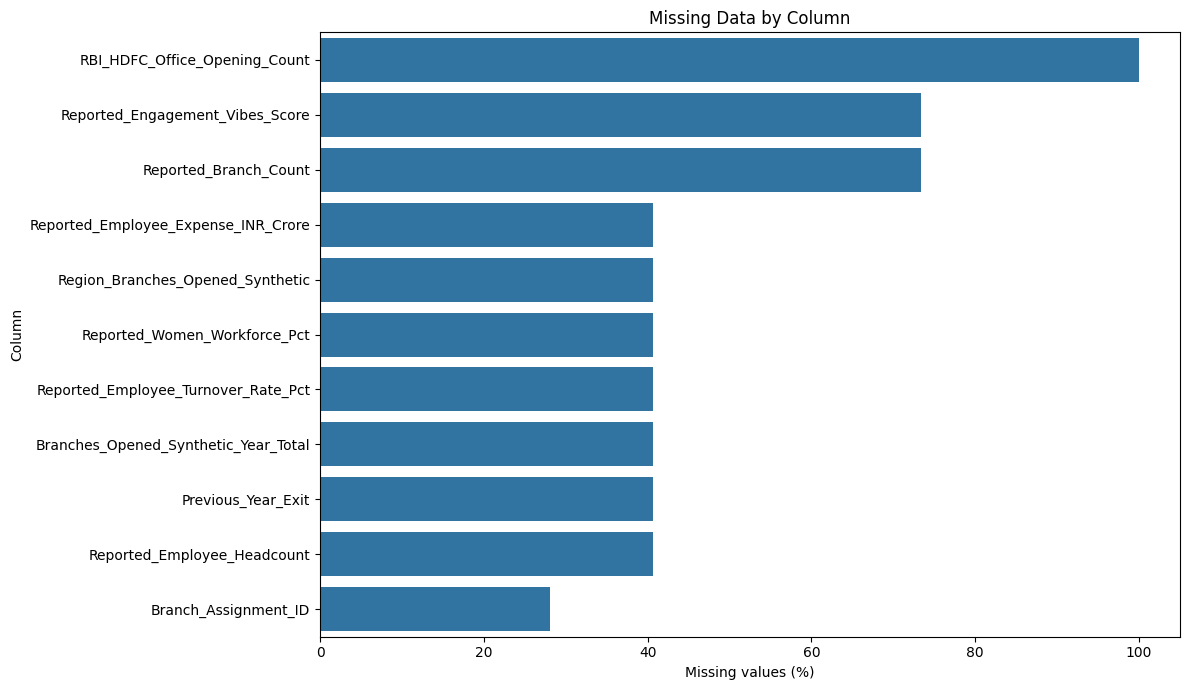

In [141]:

missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": df.isna().mean() * 100,
    "Unique_Values": df.nunique(dropna=True)
}).sort_values("Missing_Percentage", ascending=False)

display(missing_report.round(2))

# Visualise the most-missing columns
top_missing = missing_report[
    missing_report["Missing_Count"] > 0
].head(20)

if not top_missing.empty:
    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=top_missing.reset_index(),
        x="Missing_Percentage",
        y="index"
    )
    plt.title("Missing Data by Column")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()


Duplicate and consistency checks

In [142]:

# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Duplicate employee-year combinations
print(
    "Duplicate employee-year keys:",
    df.duplicated(["Employee_ID", "Financial_Year"]).sum()
)

# Employee IDs and financial years
print("Unique employee IDs:", df["Employee_ID"].nunique())
print("Financial years:", sorted(df["Financial_Year"].dropna().unique()))

# Check binary flags
binary_cols = [
    "Employee_Exit_Flag",
    "Desk_Readiness_Flag",
    "On_Job_Application_Flag",
    "Survey_Eligible_Flag",
    "Survey_Responded_Flag",
    "Talent_Review_Eligible_Flag",
    "Talent_Reviewed_Flag",
    "Internal_Hire_Flag"
]

for col in binary_cols:
    print(f"{col}: {sorted(df[col].dropna().unique())}")


Exact duplicate rows: 0
Duplicate employee-year keys: 0
Unique employee IDs: 15000
Financial years: ['FY2024', 'FY2025', 'FY2026']
Employee_Exit_Flag: [np.int64(0), np.int64(1)]
Desk_Readiness_Flag: [np.int64(0), np.int64(1)]
On_Job_Application_Flag: [np.int64(0), np.int64(1)]
Survey_Eligible_Flag: [np.int64(1)]
Survey_Responded_Flag: [np.int64(0), np.int64(1)]
Talent_Review_Eligible_Flag: [np.int64(0), np.int64(1)]
Talent_Reviewed_Flag: [np.int64(0), np.int64(1)]
Internal_Hire_Flag: [np.int64(0), np.int64(1)]


Range and logical validation

In [143]:

checks = {
    "Age outside 18-65":
        ~df["Age"].between(18, 65),

    "Negative tenure":
        df["Tenure_Years_at_FY_Start"] < 0,

    "Negative learning hours":
        df["Learning_Hours"] < 0,

    "Negative training expense":
        df["Training_Expense_INR"] < 0,

    "Pre-assessment outside 0-100":
        ~df["Learning_Assessment_Pre_Score"].between(0, 100),

    "Post-assessment outside 0-100":
        ~df["Learning_Assessment_Post_Score"].between(0, 100),

    "Response without eligibility":
        (df["Survey_Responded_Flag"] == 1) &
        (df["Survey_Eligible_Flag"] != 1),

    "Talent review without eligibility":
        (df["Talent_Reviewed_Flag"] == 1) &
        (df["Talent_Review_Eligible_Flag"] != 1),

    "On-job application without readiness":
        (df["On_Job_Application_Flag"] == 1) &
        (df["Desk_Readiness_Flag"] != 1)
}

quality_results = pd.DataFrame({
    "Check": checks.keys(),
    "Flagged_Rows": [int(mask.sum()) for mask in checks.values()]
})

display(quality_results)


,Check,Flagged_Rows
0,Age outside 18-65,0
1,Negative tenure,0
2,Negative learning hours,0
3,Negative training expense,0
4,Pre-assessment outside 0-100,0
5,Post-assessment outside 0-100,0
6,Response without eligibility,0
7,Talent review without eligibility,0
8,On-job application without readiness,0


Inspect numerical distributions and outliers

,count,mean,std,min,25%,50%,75%,max
Age,36869.0,33.308226,7.053753,21.00,28.00,33.00,38.00,59.00
Tenure_Years_at_FY_Start,36869.0,5.341143,3.270174,0.10,3.00,4.70,7.00,27.00
Annual_Base_Pay_INR_Lakh,36869.0,7.721322,5.379094,2.50,4.73,5.93,8.96,63.00
Learning_Hours,36869.0,16.730975,11.115480,0.10,8.60,14.30,22.30,95.40
Training_Expense_INR,36869.0,5027.195258,3617.631139,19.37,2445.60,4148.38,6680.67,36211.93
Learning_Assessment_Pre_Score,36869.0,60.647563,10.431098,25.00,54.00,61.00,68.00,95.00
Learning_Assessment_Post_Score,36869.0,75.087879,12.184652,25.00,67.00,75.00,84.00,100.00
Engagement_Score_Synthetic,36869.0,75.740297,10.047293,35.00,69.00,76.00,83.00,100.00


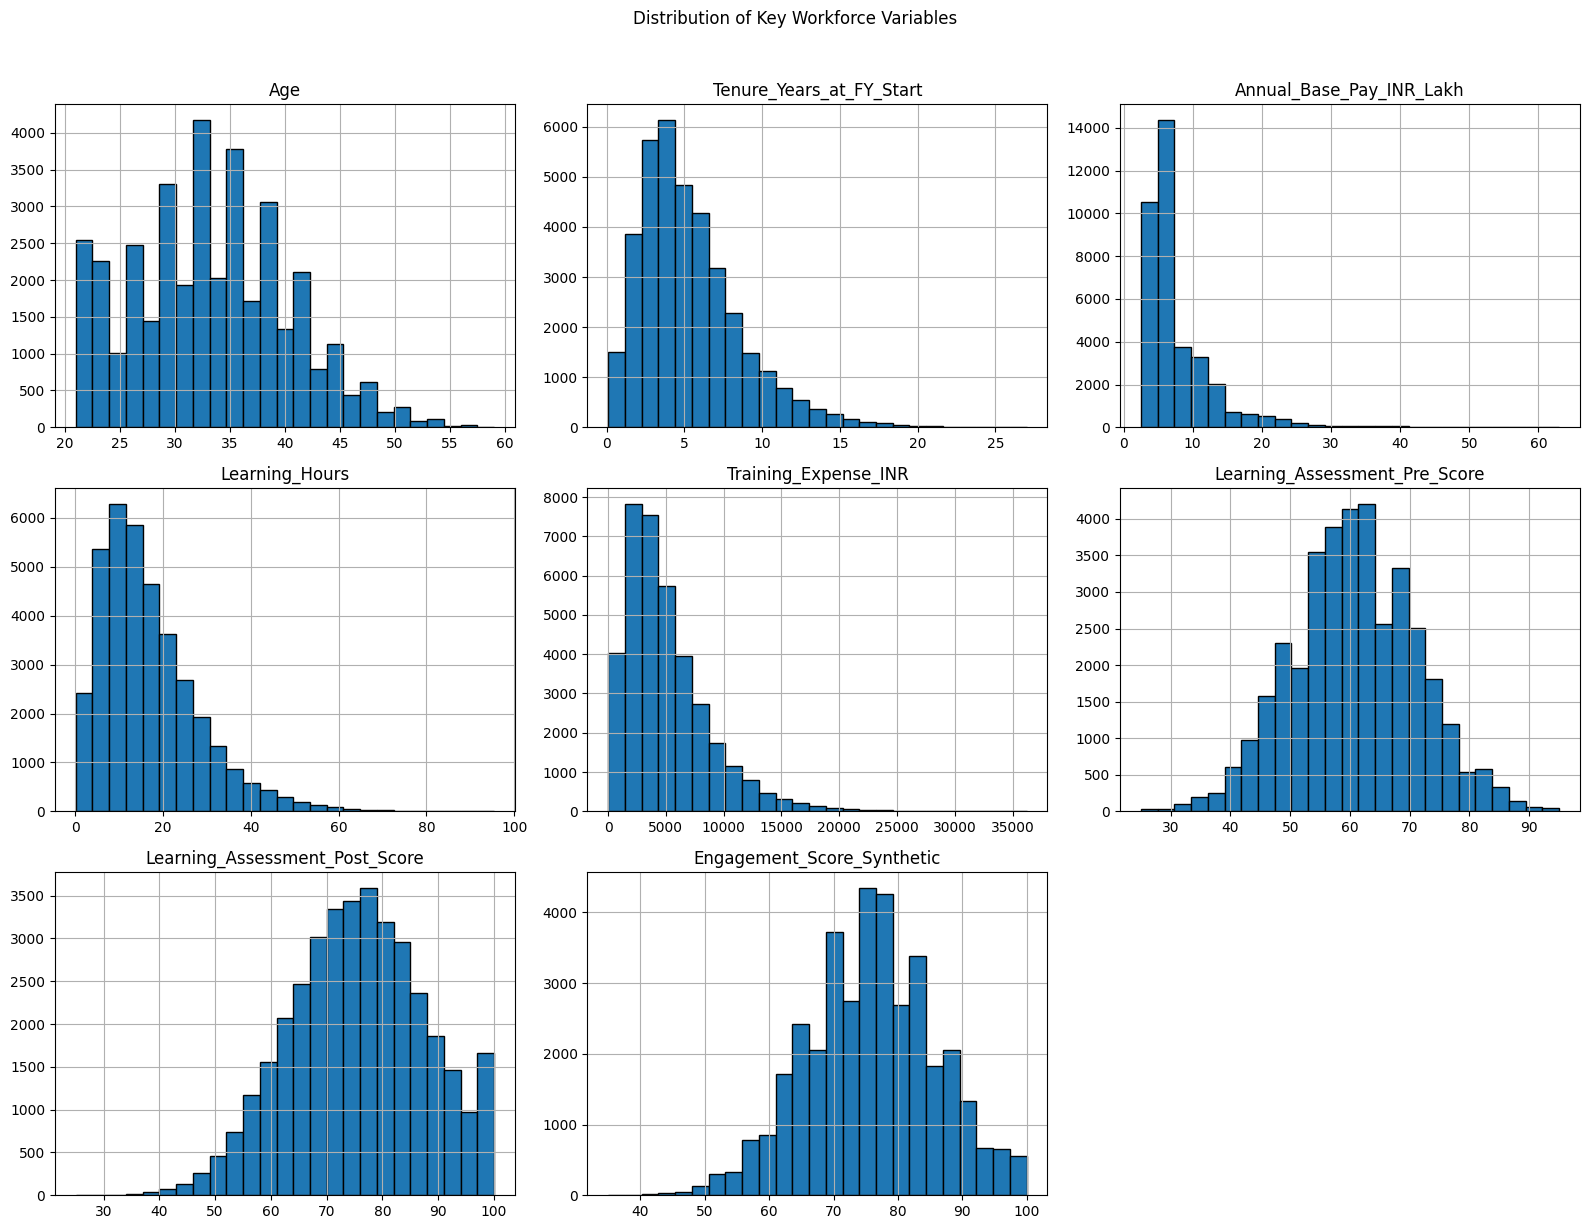

In [144]:

numeric_cols = [
    "Age",
    "Tenure_Years_at_FY_Start",
    "Annual_Base_Pay_INR_Lakh",
    "Learning_Hours",
    "Training_Expense_INR",
    "Learning_Assessment_Pre_Score",
    "Learning_Assessment_Post_Score",
    "Engagement_Score_Synthetic"
]

display(df[numeric_cols].describe().T)

df[numeric_cols].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)
plt.suptitle("Distribution of Key Workforce Variables", y=1.02)
plt.tight_layout()
plt.show()


In [145]:

outlier_summary = []

for col in numeric_cols:
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((series < lower) | (series > upper)).sum()

    outlier_summary.append({
        "Variable": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Potential_Outliers": int(count)
    })

display(pd.DataFrame(outlier_summary).round(2))


,Variable,Lower_Bound,Upper_Bound,Potential_Outliers
0,Age,13.00,53.00,98
1,Tenure_Years_at_FY_Start,-3.00,13.00,1121
2,Annual_Base_Pay_INR_Lakh,-1.62,15.31,2614
3,Learning_Hours,-11.95,42.85,1147
4,Training_Expense_INR,-3907.00,13033.28,1364
5,Learning_Assessment_Pre_Score,33.00,89.00,231
6,Learning_Assessment_Post_Score,41.50,109.50,100
7,Engagement_Score_Synthetic,48.00,104.00,102


Workforce composition and sustainability

Profile the workforce

In [146]:

categorical_cols = [
    "Age_Band",
    "Gender",
    "Region",
    "Employee_Category",
    "Job_Function",
    "Grade_Band",
    "Education"
]

for col in categorical_cols:
    print(f"\nDistribution of {col}")
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="Records")
    )



Distribution of Age_Band


,Age_Band,Records
0,30-50,25197
1,<30,11315
2,>50,357



Distribution of Gender


,Gender,Records
0,Male,25417
1,Female,11278
2,Other/Undisclosed,174



Distribution of Region


,Region,Records
0,West,11293
1,South,10230
2,North,10137
3,East,4448
4,Abroad,761


... (4 outputs left out)


Distribution of Grade_Band


,Grade_Band,Records
0,G1-G3,25522
1,G4-G6,8436
2,G7-G9,2525
3,G10+,386



Distribution of Education


,Education,Records
0,Graduate,21147
1,Postgraduate,10993
2,Professional qualification,3592
3,Other,1137


Workforce Composition

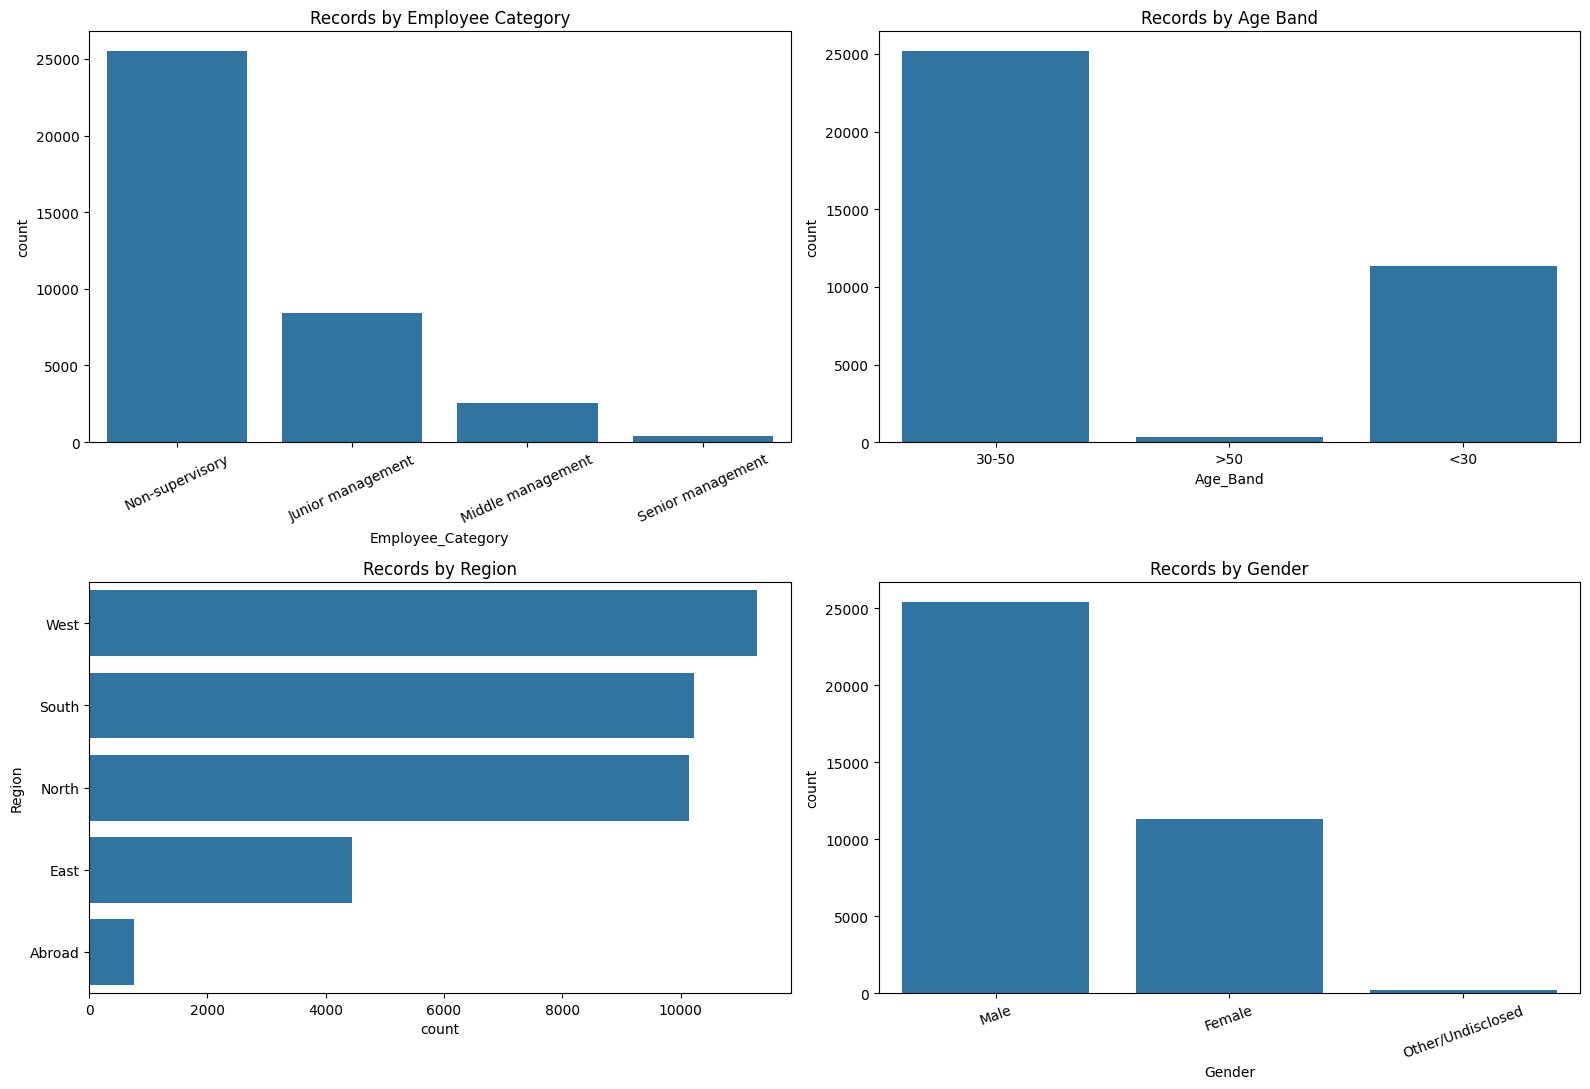

In [147]:

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.countplot(
    data=df, x="Employee_Category",
    ax=axes[0, 0], order=df["Employee_Category"].value_counts().index
)
axes[0, 0].set_title("Records by Employee Category")
axes[0, 0].tick_params(axis="x", rotation=25)

sns.countplot(data=df, x="Age_Band", ax=axes[0, 1])
axes[0, 1].set_title("Records by Age Band")

sns.countplot(
    data=df, y="Region",
    ax=axes[1, 0], order=df["Region"].value_counts().index
)
axes[1, 0].set_title("Records by Region")

sns.countplot(data=df, x="Gender", ax=axes[1, 1])
axes[1, 1].set_title("Records by Gender")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


Examine tenure and pay structure

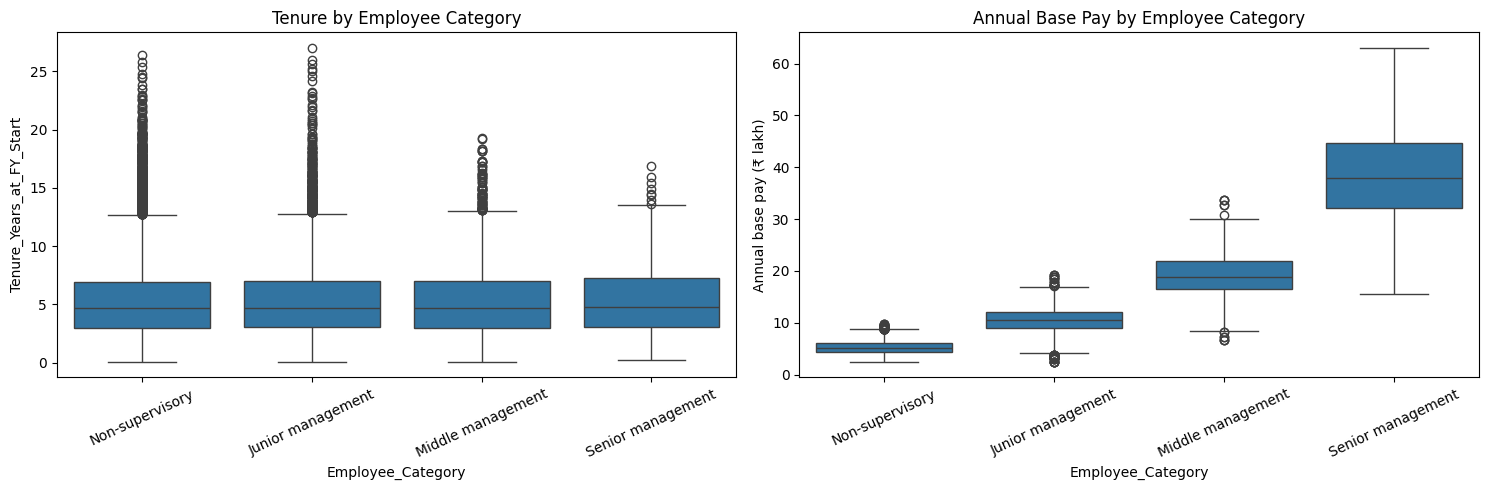

In [148]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=df, x="Employee_Category",
    y="Tenure_Years_at_FY_Start", ax=axes[0]
)
axes[0].set_title("Tenure by Employee Category")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=df, x="Employee_Category",
    y="Annual_Base_Pay_INR_Lakh", ax=axes[1]
)
axes[1].set_title("Annual Base Pay by Employee Category")
axes[1].set_ylabel("Annual base pay (₹ lakh)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


Attrition analysis

exit rate by year

,Financial_Year,Employee_Year_Records,Unique_Employees,Exit_Count,Synthetic_Exit_Rate_Pct,YoY_Change_Points
0,FY2024,15000,15000,3982,26.55,NaN
1,FY2025,12034,12034,1959,16.28,-10.27
2,FY2026,9835,9835,880,8.95,-7.33


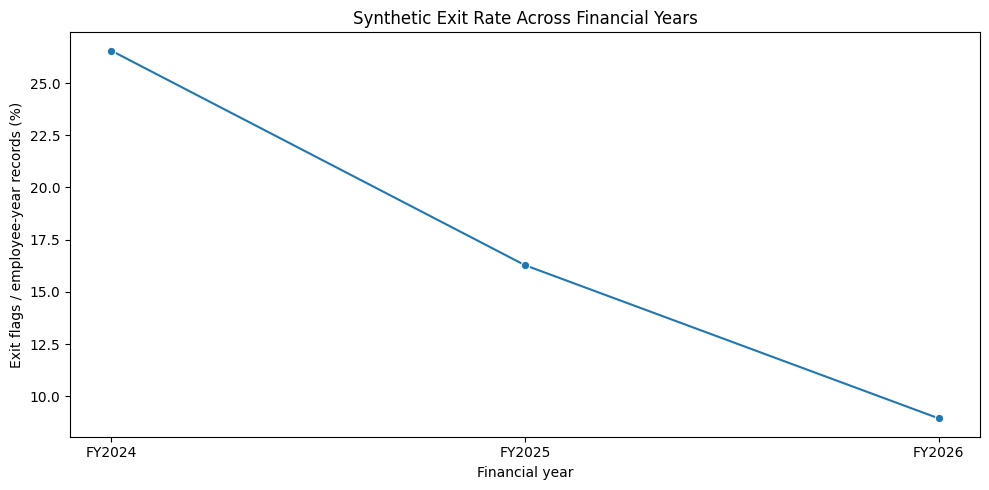

In [149]:

annual_attrition = (
    df.groupby("Financial_Year")
      .agg(
          Employee_Year_Records=("Employee_ID", "size"),
          Unique_Employees=("Employee_ID", "nunique"),
          Exit_Count=("Employee_Exit_Flag", "sum"),
          Synthetic_Exit_Rate_Pct=("Employee_Exit_Flag",
                                   lambda x: x.mean() * 100)
      )
      .reset_index()
      .sort_values("Financial_Year")
)

annual_attrition["YoY_Change_Points"] = (
    annual_attrition["Synthetic_Exit_Rate_Pct"].diff()
)

display(annual_attrition.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=annual_attrition,
    x="Financial_Year",
    y="Synthetic_Exit_Rate_Pct",
    marker="o",
    ax=ax
)
ax.set_title("Synthetic Exit Rate Across Financial Years")
ax.set_ylabel("Exit flags / employee-year records (%)")
ax.set_xlabel("Financial year")
plt.tight_layout()
plt.show()


attrition across employee segments

In [150]:

def segment_attrition(data, segment, year=None):
    subset = data.copy()

    if year is not None:
        subset = subset[subset["Financial_Year"] == year]

    overall_rate = subset["Employee_Exit_Flag"].mean() * 100

    result = (
        subset.groupby(segment, dropna=False)
        .agg(
            Employee_Year_Records=("Employee_ID", "size"),
            Exits=("Employee_Exit_Flag", "sum"),
            Exit_Rate_Pct=("Employee_Exit_Flag",
                           lambda x: x.mean() * 100)
        )
        .reset_index()
    )

    result["Gap_vs_Overall_Points"] = (
        result["Exit_Rate_Pct"] - overall_rate
    )

    result["Overall_Rate_Pct"] = overall_rate

    return result.sort_values("Exit_Rate_Pct", ascending=False)


for segment in [
    "Employee_Category", "Age_Band",
    "Gender", "Region", "Job_Function"
]:
    print(f"\nAttrition by {segment}")
    display(segment_attrition(df, segment).round(2))



Attrition by Employee_Category


,Employee_Category,Employee_Year_Records,Exits,Exit_Rate_Pct,Gap_vs_Overall_Points,Overall_Rate_Pct
2,Non-supervisory,25522,5920,23.20,4.70,18.5
1,Middle management,2525,210,8.32,-10.18,18.5
0,Junior management,8436,673,7.98,-10.52,18.5
3,Senior management,386,18,4.66,-13.84,18.5



Attrition by Age_Band


,Age_Band,Employee_Year_Records,Exits,Exit_Rate_Pct,Gap_vs_Overall_Points,Overall_Rate_Pct
1,<30,11315,3388,29.94,11.44,18.5
2,>50,357,57,15.97,-2.53,18.5
0,30-50,25197,3376,13.40,-5.10,18.5



Attrition by Gender


,Gender,Employee_Year_Records,Exits,Exit_Rate_Pct,Gap_vs_Overall_Points,Overall_Rate_Pct
1,Male,25417,4752,18.70,0.20,18.5
0,Female,11278,2042,18.11,-0.39,18.5
2,Other/Undisclosed,174,27,15.52,-2.98,18.5



Attrition by Region


,Region,Employee_Year_Records,Exits,Exit_Rate_Pct,Gap_vs_Overall_Points,Overall_Rate_Pct
3,South,10230,2270,22.19,3.69,18.5
0,Abroad,761,137,18.00,-0.50,18.5
1,East,4448,761,17.11,-1.39,18.5
2,North,10137,1731,17.08,-1.42,18.5
4,West,11293,1922,17.02,-1.48,18.5



Attrition by Job_Function


,Job_Function,Employee_Year_Records,Exits,Exit_Rate_Pct,Gap_vs_Overall_Points,Overall_Rate_Pct
5,Sales,6558,1332,20.31,1.81,18.5
4,Risk & compliance,3684,708,19.22,0.72,18.5
1,Corporate functions,2965,569,19.19,0.69,18.5
3,Operations,5552,1046,18.84,0.34,18.5
2,Customer service,4332,785,18.12,-0.38,18.5
0,Branch banking,10085,1747,17.32,-1.18,18.5
6,Technology,3693,634,17.17,-1.33,18.5


Investigate tenure and age together

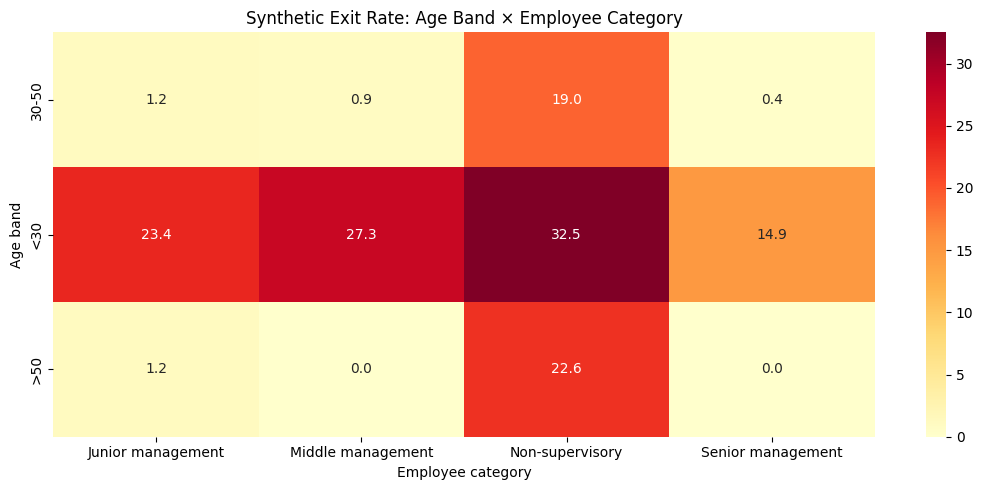

,Age_Band,Employee_Category,Records,Exits,Exit_Rate_Pct,Mean_Tenure
0,30-50,Junior management,5774,68,1.18,5.49
1,30-50,Middle management,1796,17,0.95,5.56
2,30-50,Non-supervisory,17357,3290,18.95,5.38
3,30-50,Senior management,270,1,0.37,5.30
4,<30,Junior management,2576,604,23.45,5.24
5,<30,Middle management,708,193,27.26,4.73
6,<30,Non-supervisory,7917,2574,32.51,5.17
7,<30,Senior management,114,17,14.91,5.78
8,>50,Junior management,86,1,1.16,5.34
9,>50,Middle management,21,0,0.00,4.93


In [151]:

cohort = (
    df.groupby(["Age_Band", "Employee_Category"], dropna=False)
      .agg(
          Records=("Employee_ID", "size"),
          Exits=("Employee_Exit_Flag", "sum"),
          Exit_Rate_Pct=("Employee_Exit_Flag",
                         lambda x: x.mean() * 100),
          Mean_Tenure=("Tenure_Years_at_FY_Start", "mean")
      )
      .reset_index()
)

heatmap_data = cohort.pivot(
    index="Age_Band",
    columns="Employee_Category",
    values="Exit_Rate_Pct"
)

plt.figure(figsize=(11, 5))
sns.heatmap(
    heatmap_data, annot=True, fmt=".1f",
    cmap="YlOrRd"
)
plt.title("Synthetic Exit Rate: Age Band × Employee Category")
plt.xlabel("Employee category")
plt.ylabel("Age band")
plt.tight_layout()
plt.show()

display(cohort.round(2))


exit reasons

,Synthetic_Exit_Reason,Exit_Count,Share_of_Synthetic_Exits_Pct
0,Career Growth,1899,27.84
1,Compensation,1289,18.90
2,Personal Reasons,1094,16.04
3,Workload,917,13.44
4,Other,892,13.08
5,Managerial,730,10.70


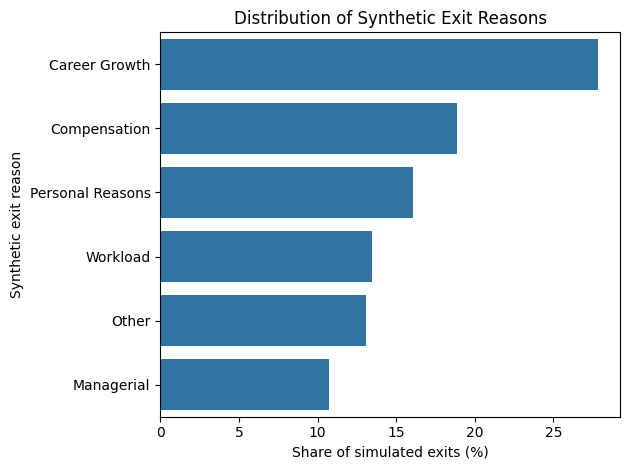

In [152]:

exits = df[df["Employee_Exit_Flag"] == 1].copy()

reason_summary = (
    exits["Exit_Reason_Synthetic"]
    .value_counts(dropna=False)
    .rename_axis("Synthetic_Exit_Reason")
    .reset_index(name="Exit_Count")
)

reason_summary["Share_of_Synthetic_Exits_Pct"] = (
    reason_summary["Exit_Count"]
    / reason_summary["Exit_Count"].sum() * 100
)

display(reason_summary.round(2))

sns.barplot(
    data=reason_summary,
    x="Share_of_Synthetic_Exits_Pct",
    y="Synthetic_Exit_Reason"
)
plt.title("Distribution of Synthetic Exit Reasons")
plt.xlabel("Share of simulated exits (%)")
plt.ylabel("Synthetic exit reason")
plt.tight_layout()
plt.show()


Workforce growth, branch expansion and capacity

In [153]:

branch_data = (
    df.groupby("Financial_Year")
      .agg(
          Synthetic_Branch_Count=(
              "Branch_Count_Synthetic_Year_Total", "first"
          ),
          Synthetic_Branches_Opened=(
              "Branches_Opened_Synthetic_Year_Total", "first"
          )
      )
      .reset_index()
      .sort_values("Financial_Year")
)

branch_data["Branch_Growth_Pct"] = (
    branch_data["Synthetic_Branch_Count"]
    .pct_change() * 100
)

display(branch_data.round(2))


,Financial_Year,Synthetic_Branch_Count,Synthetic_Branches_Opened,Branch_Growth_Pct
0,FY2024,8500,NaN,NaN
1,FY2025,9455,955.0,11.24
2,FY2026,9689,234.0,2.47


employees per branch

In [154]:


synthetic_hc = (
    df.groupby("Financial_Year")["Employee_ID"]
      .nunique()
      .reset_index(name="Synthetic_Employee_Count")
)


branch_data = (
    df.groupby("Financial_Year")
      .agg(
          Synthetic_Branch_Count=(
              "Branch_Count_Synthetic_Year_Total", "first"
          ),
          Synthetic_Branches_Opened=(
              "Branches_Opened_Synthetic_Year_Total", "first"
          )
      )
      .reset_index()
)


capacity = synthetic_hc.merge(
    branch_data,
    on="Financial_Year",
    how="left"
)


capacity["Synthetic_Employees_Per_Branch"] = (
    capacity["Synthetic_Employee_Count"]
    / capacity["Synthetic_Branch_Count"]
)

display(capacity.round(2))


,Financial_Year,Synthetic_Employee_Count,Synthetic_Branch_Count,Synthetic_Branches_Opened,Synthetic_Employees_Per_Branch
0,FY2024,15000,8500,NaN,1.76
1,FY2025,12034,9455,955.0,1.27
2,FY2026,9835,9689,234.0,1.02


Learning, training and workforce readiness

,Financial_Year,Employee_Category,Employees,Average_Learning_Hours,Median_Learning_Hours,Average_Training_Expense,Readiness_Rate_Pct
0,FY2024,Junior management,3342,16.33,13.90,4895.11,67.62
1,FY2024,Middle management,999,19.37,17.00,5912.49,68.47
2,FY2024,Non-supervisory,10508,16.44,14.10,4933.04,67.35
3,FY2024,Senior management,151,19.28,16.90,5838.70,68.87
4,FY2025,Junior management,2769,16.60,14.30,5009.81,67.21
5,FY2025,Middle management,831,20.24,17.40,5950.82,71.36
6,FY2025,Non-supervisory,8306,16.55,13.90,4984.87,67.26
7,FY2025,Senior management,128,22.04,20.05,6776.76,67.97
8,FY2026,Junior management,2325,16.48,14.00,4955.97,67.53
9,FY2026,Middle management,695,19.28,16.50,5704.02,67.91


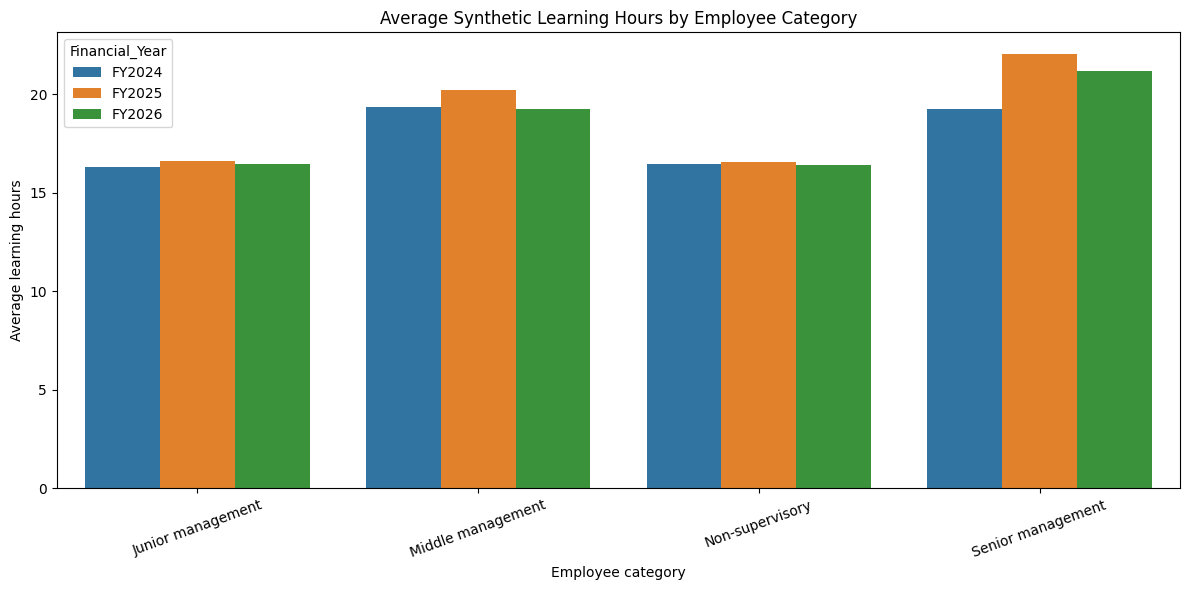

In [155]:

learning_by_category = (
    df.groupby(["Financial_Year", "Employee_Category"])
      .agg(
          Employees=("Employee_ID", "nunique"),
          Average_Learning_Hours=("Learning_Hours", "mean"),
          Median_Learning_Hours=("Learning_Hours", "median"),
          Average_Training_Expense=("Training_Expense_INR", "mean"),
          Readiness_Rate_Pct=("Desk_Readiness_Flag",
                              lambda x: x.mean() * 100)
      )
      .reset_index()
)

display(learning_by_category.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=learning_by_category,
    x="Employee_Category",
    y="Average_Learning_Hours",
    hue="Financial_Year"
)
plt.title("Average Synthetic Learning Hours by Employee Category")
plt.ylabel("Average learning hours")
plt.xlabel("Employee category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


Measure assessment improvement

In [156]:

df["Assessment_Improvement"] = (
    df["Learning_Assessment_Post_Score"]
    - df["Learning_Assessment_Pre_Score"]
)

learning_impact = (
    df.groupby("Employee_Category")
      .agg(
          Employees=("Employee_ID", "nunique"),
          Mean_Pre_Score=("Learning_Assessment_Pre_Score", "mean"),
          Mean_Post_Score=("Learning_Assessment_Post_Score", "mean"),
          Mean_Improvement=("Assessment_Improvement", "mean"),
          Readiness_Rate_Pct=("Desk_Readiness_Flag",
                              lambda x: x.mean() * 100),
          On_Job_Application_Rate_Pct=("On_Job_Application_Flag",
                                       lambda x: x.mean() * 100)
      )
      .reset_index()
)

display(learning_impact.round(2))


,Employee_Category,Employees,Mean_Pre_Score,Mean_Post_Score,Mean_Improvement,Readiness_Rate_Pct,On_Job_Application_Rate_Pct
0,Junior management,3342,60.68,75.12,14.44,67.46,52.75
1,Middle management,999,61.35,75.64,14.29,69.27,55.01
2,Non-supervisory,10508,60.56,75.01,14.45,67.24,52.18
3,Senior management,151,60.84,75.87,15.03,67.88,52.33


relationship between learning and readiness

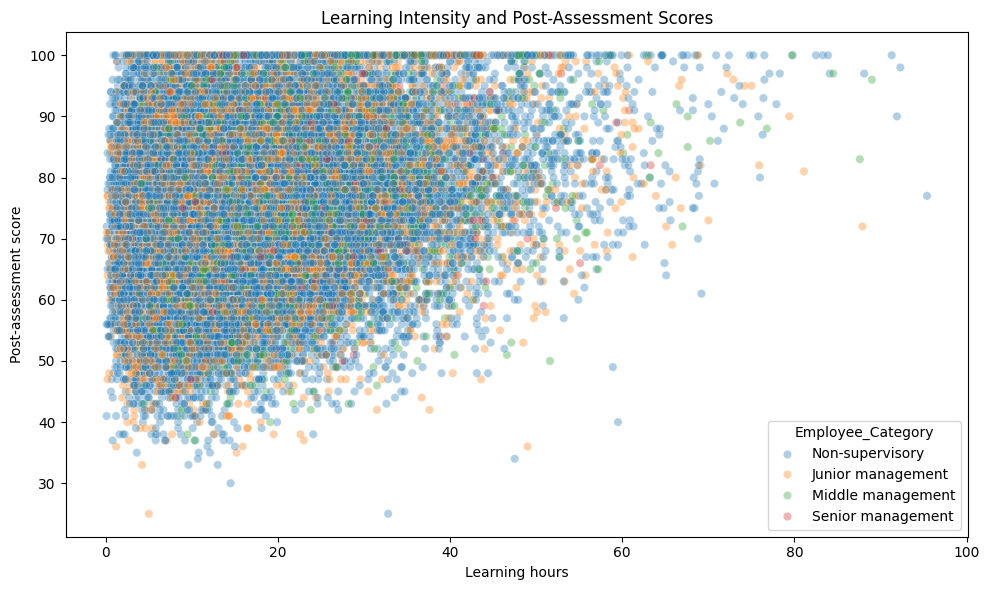

Correlation between learning hours and post-score:
0.208


In [157]:

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Learning_Hours",
    y="Learning_Assessment_Post_Score",
    hue="Employee_Category",
    alpha=0.35
)
plt.title("Learning Intensity and Post-Assessment Scores")
plt.xlabel("Learning hours")
plt.ylabel("Post-assessment score")
plt.tight_layout()
plt.show()

print("Correlation between learning hours and post-score:")
print(
    df[["Learning_Hours", "Learning_Assessment_Post_Score"]]
    .corr()
    .iloc[0, 1]
    .round(3)
)


Engagement, diversity and talent pipeline

Analyse engagement by employee segment

,Financial_Year,Employee_Category,Employees,Mean_Engagement,Median_Engagement,Survey_Eligible,Survey_Respondents,Survey_Coverage_Pct
0,FY2024,Junior management,3342,75.11,75.0,3342,2584,77.32
1,FY2024,Middle management,999,75.20,75.0,999,792,79.28
2,FY2024,Non-supervisory,10508,75.26,75.0,10508,8189,77.93
3,FY2024,Senior management,151,75.89,77.0,151,121,80.13
4,FY2025,Junior management,2769,76.19,76.0,2769,2150,77.65
5,FY2025,Middle management,831,76.12,76.0,831,662,79.66
6,FY2025,Non-supervisory,8306,76.06,76.0,8306,6501,78.27
7,FY2025,Senior management,128,75.09,75.0,128,110,85.94
8,FY2026,Junior management,2325,76.14,76.0,2325,1812,77.94
9,FY2026,Middle management,695,75.51,75.0,695,548,78.85


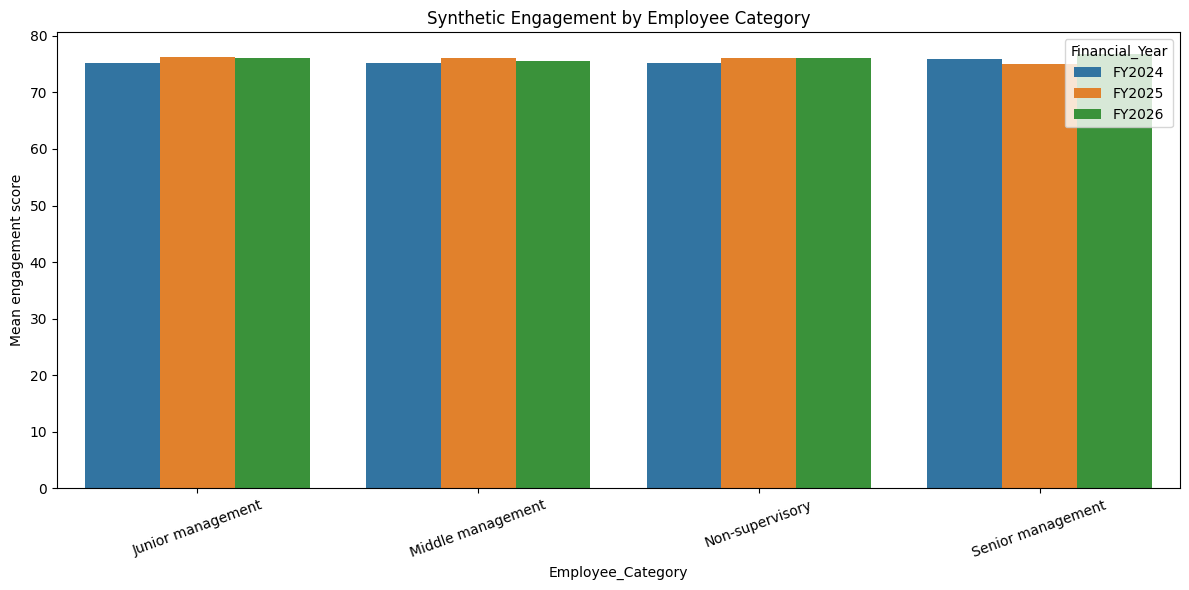

In [158]:

engagement_summary = (
    df.groupby(["Financial_Year", "Employee_Category"])
      .agg(
          Employees=("Employee_ID", "nunique"),
          Mean_Engagement=("Engagement_Score_Synthetic", "mean"),
          Median_Engagement=("Engagement_Score_Synthetic", "median"),
          Survey_Eligible=("Survey_Eligible_Flag", "sum"),
          Survey_Respondents=("Survey_Responded_Flag", "sum")
      )
      .reset_index()
)

engagement_summary["Survey_Coverage_Pct"] = (
    engagement_summary["Survey_Respondents"]
    / engagement_summary["Survey_Eligible"] * 100
)

display(engagement_summary.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=engagement_summary,
    x="Employee_Category",
    y="Mean_Engagement",
    hue="Financial_Year"
)
plt.title("Synthetic Engagement by Employee Category")
plt.ylabel("Mean engagement score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


gender representation

,Financial_Year,Gender,Employees,Exit_Rate_Pct,Workforce_Share_Pct
0,FY2024,Female,4647,25.91,30.98
1,FY2024,Male,10284,26.85,68.56
2,FY2024,Other/Undisclosed,69,24.64,0.46
3,FY2025,Female,3671,16.02,30.51
4,FY2025,Male,8305,16.44,69.01
5,FY2025,Other/Undisclosed,58,10.34,0.48
6,FY2026,Female,2960,8.45,30.10
7,FY2026,Male,6828,9.17,69.43
8,FY2026,Other/Undisclosed,47,8.51,0.48


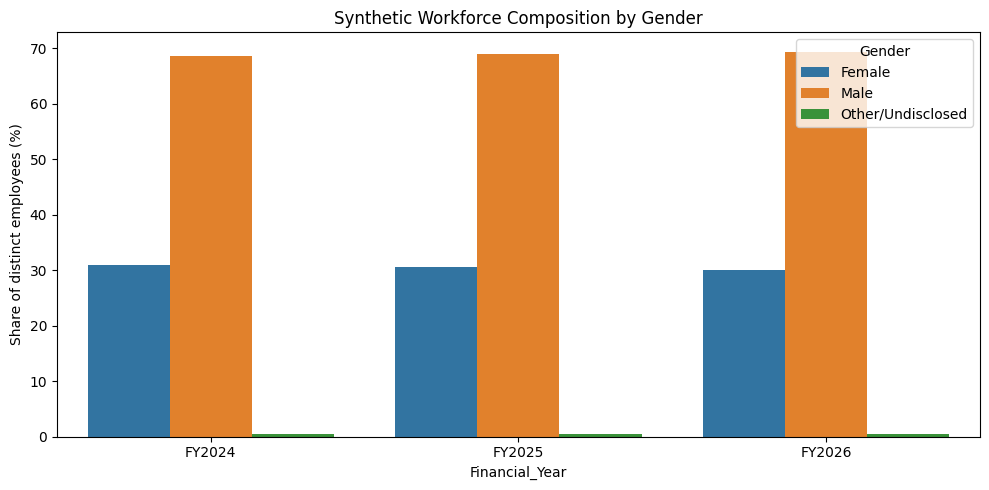

In [159]:

gender_summary = (
    df.groupby(["Financial_Year", "Gender"])
      .agg(
          Employees=("Employee_ID", "nunique"),
          Exit_Rate_Pct=("Employee_Exit_Flag",
                         lambda x: x.mean() * 100)
      )
      .reset_index()
)

gender_summary["Workforce_Share_Pct"] = (
    gender_summary["Employees"]
    / gender_summary.groupby("Financial_Year")["Employees"].transform("sum")
    * 100
)

display(gender_summary.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=gender_summary,
    x="Financial_Year",
    y="Workforce_Share_Pct",
    hue="Gender"
)
plt.title("Synthetic Workforce Composition by Gender")
plt.ylabel("Share of distinct employees (%)")
plt.tight_layout()
plt.show()


talent-review coverage and internal hiring

In [160]:

talent_summary = (
    df.groupby(["Financial_Year", "Employee_Category"])
      .agg(
          Eligible_For_Review=("Talent_Review_Eligible_Flag", "sum"),
          Reviewed=("Talent_Reviewed_Flag", "sum"),
          Internal_Hire_Events=("Internal_Hire_Flag", "sum"),
          Hire_Events_Synthetic=("Total_Hire_Events_Synthetic", "sum")
      )
      .reset_index()
)

talent_summary["Talent_Review_Coverage_Pct"] = np.where(
    talent_summary["Eligible_For_Review"] > 0,
    talent_summary["Reviewed"]
    / talent_summary["Eligible_For_Review"] * 100,
    np.nan
)

talent_summary["Internal_Hiring_Rate_Pct"] = np.where(
    talent_summary["Hire_Events_Synthetic"] > 0,
    talent_summary["Internal_Hire_Events"]
    / talent_summary["Hire_Events_Synthetic"] * 100,
    np.nan
)

display(talent_summary.round(2))


,Financial_Year,Employee_Category,Eligible_For_Review,Reviewed,Internal_Hire_Events,Hire_Events_Synthetic,Talent_Review_Coverage_Pct,Internal_Hiring_Rate_Pct
0,FY2024,Junior management,3342,2186,0,263,65.41,0.00
1,FY2024,Middle management,999,634,0,84,63.46,0.00
2,FY2024,Non-supervisory,0,0,0,835,NaN,0.00
3,FY2024,Senior management,151,116,0,14,76.82,0.00
4,FY2025,Junior management,2769,1800,597,238,65.01,250.84
5,FY2025,Middle management,831,553,183,61,66.55,300.00
6,FY2025,Non-supervisory,0,0,1019,642,NaN,158.72
7,FY2025,Senior management,128,103,16,8,80.47,200.00
8,FY2026,Junior management,2325,1503,543,187,64.65,290.37
9,FY2026,Middle management,695,432,151,67,62.16,225.37


reported employee expense

In [161]:

reported_cols = [
    "Reported_Employee_Expense_INR_Crore",
    "Reported_Employee_Headcount",
    "Reported_Branch_Count",
    "Reported_Employee_Turnover_Rate_Pct",
    "Reported_Learning_Hours_Total",
    "Reported_Training_Expense_INR_Crore",
    "Reported_Training_Expense_Per_Employee_INR",
    "Reported_Engagement_Vibes_Score",
    "Reported_Women_Workforce_Pct"
]

annual_reported = (
    df.groupby("Financial_Year")[reported_cols]
      .first()
      .reset_index()
      .sort_values("Financial_Year")
)

display(annual_reported)


,Financial_Year,Reported_Employee_Expense_INR_Crore,Reported_Employee_Headcount,Reported_Branch_Count,Reported_Employee_Turnover_Rate_Pct,Reported_Learning_Hours_Total,Reported_Training_Expense_INR_Crore,Reported_Training_Expense_Per_Employee_INR,Reported_Engagement_Vibes_Score,Reported_Women_Workforce_Pct
0,FY2024,NaN,NaN,NaN,NaN,6654452,421,19708,NaN,NaN
1,FY2025,23900.5,214521.0,NaN,22.6,12495372,473,22035,NaN,26.14
2,FY2026,26050.0,211178.0,9689.0,23.1,13653941,363,17212,86.0,26.60


In [162]:

annual_reported["Employee_Expense_Per_Employee_INR"] = (
    annual_reported["Reported_Employee_Expense_INR_Crore"]
    * 10_000_000
    / annual_reported["Reported_Employee_Headcount"]
)

display(annual_reported[[
    "Financial_Year",
    "Reported_Employee_Expense_INR_Crore",
    "Reported_Employee_Headcount",
    "Employee_Expense_Per_Employee_INR"
]].round(2))


,Financial_Year,Reported_Employee_Expense_INR_Crore,Reported_Employee_Headcount,Employee_Expense_Per_Employee_INR
0,FY2024,NaN,NaN,NaN
1,FY2025,23900.5,214521.0,1114133.35
2,FY2026,26050.0,211178.0,1233556.53


workforce costs with learning investment

In [163]:

cost_metrics = annual_reported[[
    "Financial_Year",
    "Reported_Employee_Expense_INR_Crore",
    "Reported_Training_Expense_INR_Crore",
    "Reported_Training_Expense_Per_Employee_INR",
    "Reported_Learning_Hours_Total"
]].copy()

cost_metrics["Training_Expense_as_Pct_of_Employee_Expense"] = (
    cost_metrics["Reported_Training_Expense_INR_Crore"]
    / cost_metrics["Reported_Employee_Expense_INR_Crore"]
    * 100
)

display(cost_metrics.round(2))


,Financial_Year,Reported_Employee_Expense_INR_Crore,Reported_Training_Expense_INR_Crore,Reported_Training_Expense_Per_Employee_INR,Reported_Learning_Hours_Total,Training_Expense_as_Pct_of_Employee_Expense
0,FY2024,NaN,421,19708,6654452,NaN
1,FY2025,23900.5,473,22035,12495372,1.98
2,FY2026,26050.0,363,17212,13653941,1.39


attrition-risk profile

,Exploratory_Risk_Factor_Count,Records,Exit_Count,Exit_Rate_Pct
0,0,15073,1323,8.78
1,1,15581,2735,17.55
2,2,5417,2090,38.58
3,3,749,624,83.31
4,4,49,49,100.00


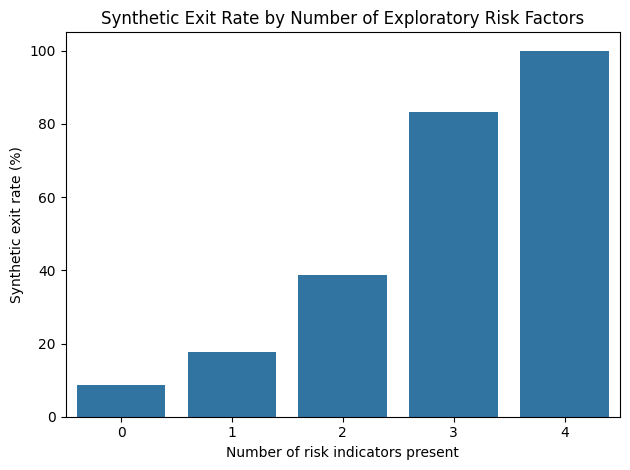

In [164]:

risk_df = df.copy()

risk_df["Early_Career_Flag"] = (
    risk_df["Tenure_Years_at_FY_Start"] < 2
).astype(int)

risk_df["Young_Workforce_Flag"] = (
    risk_df["Age"] < 30
).astype(int)

risk_df["Low_Engagement_Flag"] = (
    risk_df["Engagement_Score_Synthetic"] < 60
).astype(int)

risk_df["Low_Learning_Flag"] = (
    risk_df["Learning_Hours"] < 10
).astype(int)

risk_factors = [
    "Early_Career_Flag",
    "Young_Workforce_Flag",
    "Low_Engagement_Flag",
    "Low_Learning_Flag"
]

risk_df["Exploratory_Risk_Factor_Count"] = (
    risk_df[risk_factors].sum(axis=1)
)

risk_profile = (
    risk_df.groupby("Exploratory_Risk_Factor_Count")
      .agg(
          Records=("Employee_ID", "size"),
          Exit_Count=("Employee_Exit_Flag", "sum"),
          Exit_Rate_Pct=("Employee_Exit_Flag",
                         lambda x: x.mean() * 100)
      )
      .reset_index()
)

display(risk_profile.round(2))

sns.barplot(
    data=risk_profile,
    x="Exploratory_Risk_Factor_Count",
    y="Exit_Rate_Pct"
)
plt.title("Synthetic Exit Rate by Number of Exploratory Risk Factors")
plt.xlabel("Number of risk indicators present")
plt.ylabel("Synthetic exit rate (%)")
plt.tight_layout()
plt.show()


correlation structure

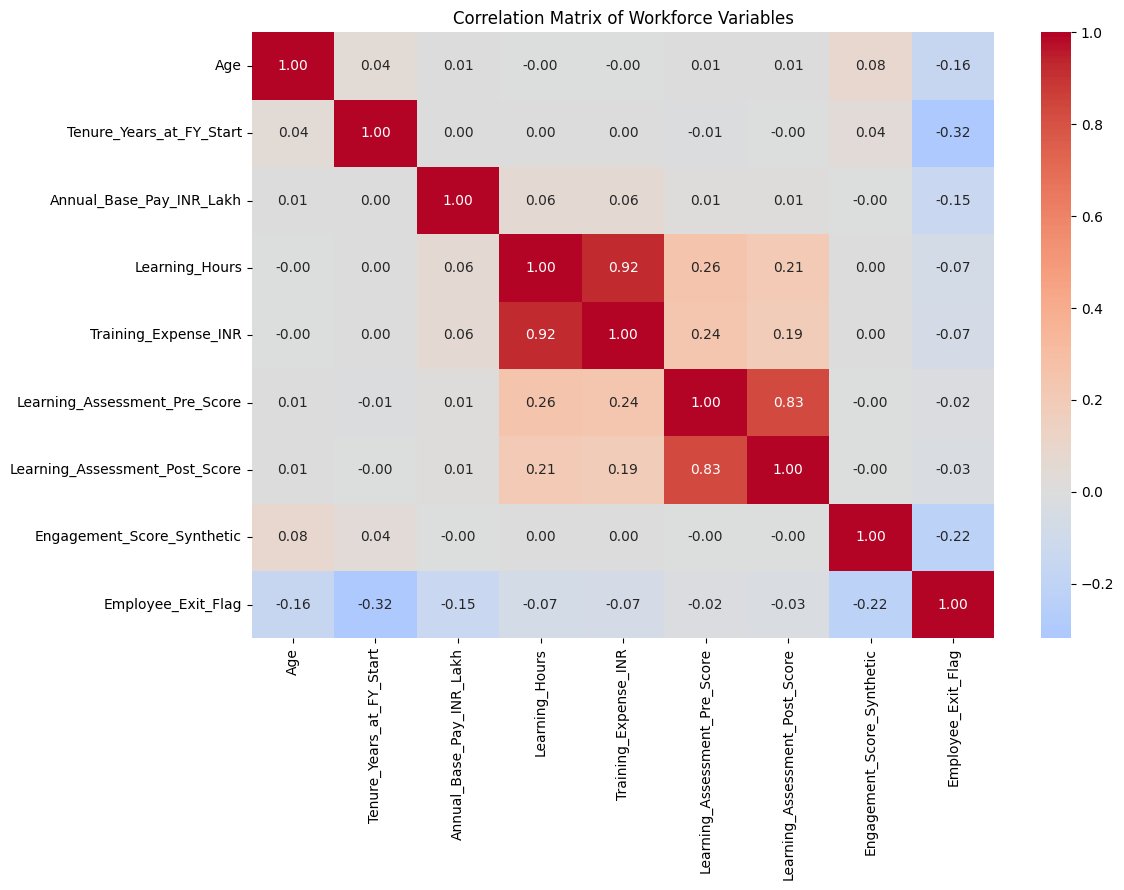

In [165]:

corr_cols = [
    "Age",
    "Tenure_Years_at_FY_Start",
    "Annual_Base_Pay_INR_Lakh",
    "Learning_Hours",
    "Training_Expense_INR",
    "Learning_Assessment_Pre_Score",
    "Learning_Assessment_Post_Score",
    "Engagement_Score_Synthetic",
    "Employee_Exit_Flag"
]

correlation_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Workforce Variables")
plt.tight_layout()
plt.show()


exit patterns by multiple dimensions

In [166]:

multi_segment = (
    df.groupby(
        ["Financial_Year", "Region", "Age_Band", "Employee_Category"],
        dropna=False
    )
    .agg(
        Records=("Employee_ID", "size"),
        Exits=("Employee_Exit_Flag", "sum"),
        Exit_Rate_Pct=("Employee_Exit_Flag",
                       lambda x: x.mean() * 100)
    )
    .reset_index()
)

# Suppress very small groups for descriptive stability
multi_segment_filtered = multi_segment[
    multi_segment["Records"] >= 30
].copy()

display(
    multi_segment_filtered.sort_values(
        "Exit_Rate_Pct", ascending=False
    ).head(20).round(2)
)


,Financial_Year,Region,Age_Band,Employee_Category,Records,Exits,Exit_Rate_Pct
6,FY2024,Abroad,<30,Non-supervisory,72,37,51.39
36,FY2024,South,<30,Non-supervisory,1123,530,47.20
25,FY2024,North,<30,Non-supervisory,1060,433,40.85
47,FY2024,West,<30,Non-supervisory,1207,484,40.10
15,FY2024,East,<30,Non-supervisory,453,178,39.29
24,FY2024,North,<30,Middle management,103,40,38.83
13,FY2024,East,<30,Junior management,164,59,35.98
14,FY2024,East,<30,Middle management,51,18,35.29
34,FY2024,South,<30,Junior management,324,109,33.64
23,FY2024,North,<30,Junior management,345,116,33.62


whether segment differences are statistically distinguishable

In [167]:

from scipy.stats import mannwhitneyu

print("Mann-Whitney U test imported successfully!")


Mann-Whitney U test imported successfully!


In [168]:

exit_engagement = df.loc[
    df["Employee_Exit_Flag"] == 1,
    "Engagement_Score_Synthetic"
].dropna()

stay_engagement = df.loc[
    df["Employee_Exit_Flag"] == 0,
    "Engagement_Score_Synthetic"
].dropna()

if len(exit_engagement) > 0 and len(stay_engagement) > 0:
    statistic, p_value = mannwhitneyu(
        exit_engagement,
        stay_engagement,
        alternative="two-sided"
    )

    print("Exit-group median engagement:",
          exit_engagement.median())
    print("Non-exit-group median engagement:",
          stay_engagement.median())
    print("Mann–Whitney U statistic:", statistic)
    print("P-value:", p_value)


Exit-group median engagement: 71.0
Non-exit-group median engagement: 77.0
Mann–Whitney U statistic: 71605038.5
P-value: 0.0


"BUSINESS ANALYSIS"


In [169]:
#ANALYSIS 1: ATTRITION DRIVER STRENGTH

from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def cramers_v(x, y):
    """Calculate bias-corrected Cramer's V."""

    table = pd.crosstab(x, y)

    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(table)[0]
    n = table.sum().sum()

    phi2 = chi2 / n
    r, k = table.shape

    phi2corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(kcorr - 1, rcorr - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2corr / denominator)


# Use categorical variables available in the current dataframe
candidate_categorical_drivers = [
    "Age_Band_Clean",
    "Gender",
    "Region",
    "Employee_Category",
    "Job_Function",
    "Grade_Band",
    "Education"
]

categorical_drivers = [
    col for col in candidate_categorical_drivers
    if col in df.columns
]


driver_results = []

for col in categorical_drivers:

    temp = df[
        [col, "Employee_Exit_Flag"]
    ].dropna()

    contingency = pd.crosstab(
        temp[col],
        temp["Employee_Exit_Flag"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    cv = cramers_v(
        temp[col],
        temp["Employee_Exit_Flag"]
    )

    driver_results.append({
        "Factor": col,
        "Cramers_V": cv,
        "P_Value": p_value,
        "Statistically_Significant": (
            "Yes" if p_value < 0.05 else "No"
        )
    })


driver_results = pd.DataFrame(
    driver_results
).sort_values(
    "Cramers_V",
    ascending=False
).reset_index(drop=True)


display(
    driver_results.round(4)
)

,Factor,Cramers_V,P_Value,Statistically_Significant
0,Age_Band_Clean,0.1960,0.0000,Yes
1,Grade_Band,0.1813,0.0000,Yes
2,Employee_Category,0.1813,0.0000,Yes
3,Region,0.0581,0.0000,Yes
4,Job_Function,0.0260,0.0000,Yes
5,Gender,0.0048,0.2422,No
6,Education,0.0030,0.3444,No


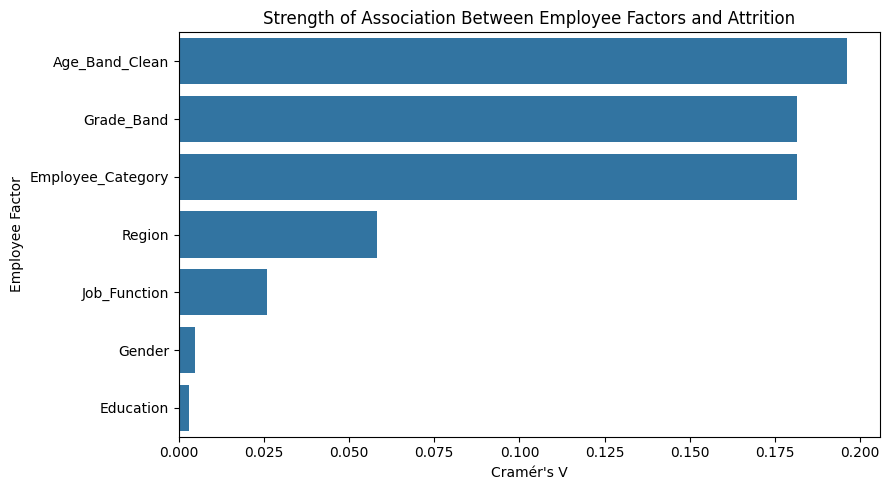

In [170]:
#Visualisation of Driver Strenghth

plt.figure(figsize=(9, 5))

sns.barplot(
    data=driver_results,
    x="Cramers_V",
    y="Factor"
)

plt.title(
    "Strength of Association Between Employee Factors and Attrition"
)

plt.xlabel("Cramér's V")
plt.ylabel("Employee Factor")

plt.tight_layout()
plt.show()

In [171]:
#2. Attrition Gap Analysis

overall_attrition = (
    df["Employee_Exit_Flag"].mean() * 100
)

print(
    f"Overall Synthetic Attrition Rate: "
    f"{overall_attrition:.2f}%"
)

Overall Synthetic Attrition Rate: 18.50%


In [172]:
def attrition_gap_analysis(data, variable):

    result = (
        data.groupby(
            variable,
            dropna=False
        )
        .agg(
            Employee_Records=(
                "Employee_ID",
                "size"
            ),
            Exits=(
                "Employee_Exit_Flag",
                "sum"
            ),
            Attrition_Rate=(
                "Employee_Exit_Flag",
                "mean"
            )
        )
        .reset_index()
    )

    result["Attrition_Rate_Pct"] = (
        result["Attrition_Rate"] * 100
    )

    result["Attrition_Gap_Points"] = (
        result["Attrition_Rate_Pct"]
        - overall_attrition
    )

    return (
        result
        .sort_values(
            "Attrition_Gap_Points",
            ascending=False
        )
    )

In [173]:
gap_variables = [
    "Age_Band_Clean",
    "Employee_Category",
    "Region",
    "Gender",
    "Job_Function"
]

gap_results = {}

for variable in gap_variables:

    if variable in df.columns:

        result = attrition_gap_analysis(
            df,
            variable
        )

        gap_results[variable] = result

        print("\n" + "=" * 70)
        print(
            f"ATTRITION GAP BY {variable.upper()}"
        )
        print("=" * 70)

        display(
            result[
                [
                    variable,
                    "Employee_Records",
                    "Exits",
                    "Attrition_Rate_Pct",
                    "Attrition_Gap_Points"
                ]
            ].round(2)
        )


ATTRITION GAP BY AGE_BAND_CLEAN


/tmp/ipykernel_496/1169076624.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby(


,Age_Band_Clean,Employee_Records,Exits,Attrition_Rate_Pct,Attrition_Gap_Points
0,Under 30,11315,3388,29.94,11.44
2,Over 50,357,57,15.97,-2.53
1,30–50,25197,3376,13.40,-5.10



ATTRITION GAP BY EMPLOYEE_CATEGORY


,Employee_Category,Employee_Records,Exits,Attrition_Rate_Pct,Attrition_Gap_Points
2,Non-supervisory,25522,5920,23.20,4.70
1,Middle management,2525,210,8.32,-10.18
0,Junior management,8436,673,7.98,-10.52
3,Senior management,386,18,4.66,-13.84



ATTRITION GAP BY REGION


,Region,Employee_Records,Exits,Attrition_Rate_Pct,Attrition_Gap_Points
3,South,10230,2270,22.19,3.69
0,Abroad,761,137,18.00,-0.50
1,East,4448,761,17.11,-1.39
2,North,10137,1731,17.08,-1.42
4,West,11293,1922,17.02,-1.48



ATTRITION GAP BY GENDER


,Gender,Employee_Records,Exits,Attrition_Rate_Pct,Attrition_Gap_Points
1,Male,25417,4752,18.70,0.20
0,Female,11278,2042,18.11,-0.39
2,Other/Undisclosed,174,27,15.52,-2.98



ATTRITION GAP BY JOB_FUNCTION


,Job_Function,Employee_Records,Exits,Attrition_Rate_Pct,Attrition_Gap_Points
5,Sales,6558,1332,20.31,1.81
4,Risk & compliance,3684,708,19.22,0.72
1,Corporate functions,2965,569,19.19,0.69
3,Operations,5552,1046,18.84,0.34
2,Customer service,4332,785,18.12,-0.38
0,Branch banking,10085,1747,17.32,-1.18
6,Technology,3693,634,17.17,-1.33


In [174]:
#3. High-Risk Cohort Analysis

cohort_variables = [
    col for col in [
        "Age_Band_Clean",
        "Employee_Category",
        "Region"
    ]
    if col in df.columns
]


high_risk_cohorts = (
    df.groupby(
        cohort_variables,
        dropna=False
    )
    .agg(
        Employee_Records=(
            "Employee_ID",
            "size"
        ),
        Exits=(
            "Employee_Exit_Flag",
            "sum"
        ),
        Attrition_Rate=(
            "Employee_Exit_Flag",
            "mean"
        )
    )
    .reset_index()
)


high_risk_cohorts["Attrition_Rate_Pct"] = (
    high_risk_cohorts["Attrition_Rate"]
    * 100
)

high_risk_cohorts["Attrition_Gap_Points"] = (
    high_risk_cohorts["Attrition_Rate_Pct"]
    - overall_attrition
)


# Remove very small cohorts
high_risk_cohorts = (
    high_risk_cohorts[
        high_risk_cohorts[
            "Employee_Records"
        ] >= 50
    ]
    .sort_values(
        "Attrition_Rate_Pct",
        ascending=False
    )
)


display(
    high_risk_cohorts[
        cohort_variables
        + [
            "Employee_Records",
            "Exits",
            "Attrition_Rate_Pct",
            "Attrition_Gap_Points"
        ]
    ]
    .head(15)
    .round(2)
)

/tmp/ipykernel_496/642612932.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(


,Age_Band_Clean,Employee_Category,Region,Employee_Records,Exits,Attrition_Rate_Pct,Attrition_Gap_Points
13,Under 30,Non-supervisory,South,2223,852,38.33,19.83
10,Under 30,Non-supervisory,Abroad,176,56,31.82,13.32
14,Under 30,Non-supervisory,West,2388,727,30.44,11.94
11,Under 30,Non-supervisory,East,965,293,30.36,11.86
12,Under 30,Non-supervisory,North,2165,646,29.84,11.34
7,Under 30,Middle management,North,208,62,29.81,11.31
8,Under 30,Middle management,South,199,55,27.64,9.14
6,Under 30,Middle management,East,113,31,27.43,8.93
52,Over 50,Non-supervisory,North,60,16,26.67,8.17
53,Over 50,Non-supervisory,South,65,17,26.15,7.65


In [175]:
#4. Engagement × Attrition Deep Analysis

analysis_df = df.copy()


analysis_df["Engagement_Quartile"] = pd.qcut(
    analysis_df[
        "Engagement_Score_Synthetic"
    ],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4 - Highest"
    ],
    duplicates="drop"
)


engagement_attrition = (
    analysis_df.groupby(
        "Engagement_Quartile",
        observed=False
    )
    .agg(
        Employees=(
            "Employee_ID",
            "size"
        ),
        Average_Engagement=(
            "Engagement_Score_Synthetic",
            "mean"
        ),
        Exits=(
            "Employee_Exit_Flag",
            "sum"
        ),
        Attrition_Rate=(
            "Employee_Exit_Flag",
            "mean"
        )
    )
    .reset_index()
)


engagement_attrition[
    "Attrition_Rate_Pct"
] = (
    engagement_attrition[
        "Attrition_Rate"
    ] * 100
)


display(
    engagement_attrition.round(2)
)

,Engagement_Quartile,Employees,Average_Engagement,Exits,Attrition_Rate,Attrition_Rate_Pct
0,Q1 - Lowest,9825,63.28,3176,0.32,32.33
1,Q2,9630,73.11,1387,0.14,14.40
2,Q3,9300,79.85,1203,0.13,12.94
3,Q4 - Highest,8114,89.24,1055,0.13,13.00


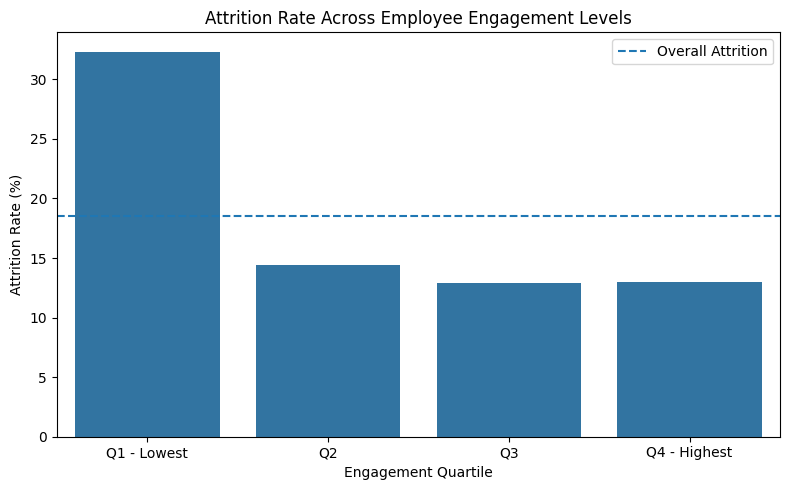

In [176]:
#Visualisation

plt.figure(figsize=(8, 5))

sns.barplot(
    data=engagement_attrition,
    x="Engagement_Quartile",
    y="Attrition_Rate_Pct"
)

plt.axhline(
    overall_attrition,
    linestyle="--",
    label="Overall Attrition"
)

plt.title(
    "Attrition Rate Across Employee Engagement Levels"
)

plt.xlabel("Engagement Quartile")
plt.ylabel("Attrition Rate (%)")

plt.legend()

plt.tight_layout()
plt.show()

In [177]:
#5. Learning Effectiveness Analysis

learning_metrics = [
    col for col in [
        "Learning_Hours",
        "Assessment_Improvement",
        "Desk_Readiness_Flag",
        "On_Job_Application_Flag"
    ]
    if col in analysis_df.columns
]


learning_by_exit = (
    analysis_df.groupby(
        "Employee_Exit_Flag"
    )[learning_metrics]
    .mean()
    .T
)


learning_by_exit.columns = [
    "Stayed",
    "Exited"
]

learning_by_exit[
    "Difference_Exited_Minus_Stayed"
] = (
    learning_by_exit["Exited"]
    - learning_by_exit["Stayed"]
)


display(
    learning_by_exit.round(3)
)

,Stayed,Exited,Difference_Exited_Minus_Stayed
Learning_Hours,17.107,15.073,-2.034
Assessment_Improvement,14.510,14.131,-0.379
Desk_Readiness_Flag,0.679,0.656,-0.023
On_Job_Application_Flag,0.529,0.508,-0.020


In [178]:
#Learning intensity groups

analysis_df["Learning_Hours_Quartile"] = pd.qcut(
    analysis_df["Learning_Hours"],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4 - Highest"
    ],
    duplicates="drop"
)


learning_effectiveness = (
    analysis_df.groupby(
        "Learning_Hours_Quartile",
        observed=False
    )
    .agg(
        Employees=(
            "Employee_ID",
            "size"
        ),
        Avg_Learning_Hours=(
            "Learning_Hours",
            "mean"
        ),
        Avg_Assessment_Improvement=(
            "Assessment_Improvement",
            "mean"
        ),
        Desk_Readiness_Rate=(
            "Desk_Readiness_Flag",
            "mean"
        ),
        On_Job_Application_Rate=(
            "On_Job_Application_Flag",
            "mean"
        ),
        Attrition_Rate=(
            "Employee_Exit_Flag",
            "mean"
        )
    )
    .reset_index()
)


for col in [
    "Desk_Readiness_Rate",
    "On_Job_Application_Rate",
    "Attrition_Rate"
]:
    learning_effectiveness[col] *= 100


display(
    learning_effectiveness.round(2)
)

,Learning_Hours_Quartile,Employees,Avg_Learning_Hours,Avg_Assessment_Improvement,Desk_Readiness_Rate,On_Job_Application_Rate,Attrition_Rate
0,Q1 - Lowest,9240,5.44,14.66,59.74,46.63,19.89
1,Q2,9237,11.44,14.42,64.13,49.73,19.75
2,Q3,9218,18.00,14.42,68.60,53.66,20.00
3,Q4 - Highest,9174,32.16,14.26,77.34,60.05,14.33


In [179]:
#6. Engagement × Learning Interaction

engagement_median = (
    analysis_df[
        "Engagement_Score_Synthetic"
    ].median()
)

learning_median = (
    analysis_df[
        "Learning_Hours"
    ].median()
)


analysis_df[
    "Engagement_Level"
] = np.where(
    analysis_df[
        "Engagement_Score_Synthetic"
    ] >= engagement_median,
    "High Engagement",
    "Low Engagement"
)


analysis_df[
    "Learning_Level"
] = np.where(
    analysis_df[
        "Learning_Hours"
    ] >= learning_median,
    "High Learning",
    "Low Learning"
)


analysis_df[
    "Engagement_Learning_Profile"
] = (
    analysis_df[
        "Engagement_Level"
    ]
    + " + "
    + analysis_df[
        "Learning_Level"
    ]
)


interaction_analysis = (
    analysis_df.groupby(
        "Engagement_Learning_Profile"
    )
    .agg(
        Employees=(
            "Employee_ID",
            "size"
        ),
        Exits=(
            "Employee_Exit_Flag",
            "sum"
        ),
        Attrition_Rate=(
            "Employee_Exit_Flag",
            "mean"
        ),
        Avg_Assessment_Improvement=(
            "Assessment_Improvement",
            "mean"
        )
    )
    .reset_index()
)


interaction_analysis[
    "Attrition_Rate_Pct"
] = (
    interaction_analysis[
        "Attrition_Rate"
    ] * 100
)


interaction_analysis[
    "Attrition_Gap_Points"
] = (
    interaction_analysis[
        "Attrition_Rate_Pct"
    ]
    - overall_attrition
)


interaction_analysis = (
    interaction_analysis
    .sort_values(
        "Attrition_Rate_Pct",
        ascending=False
    )
)


display(
    interaction_analysis.round(2)
)

,Engagement_Learning_Profile,Employees,Exits,Attrition_Rate,Avg_Assessment_Improvement,Attrition_Rate_Pct,Attrition_Gap_Points
3,Low Engagement + Low Learning,9048,2344,0.26,14.55,25.91,7.41
2,Low Engagement + High Learning,8935,2028,0.23,14.38,22.70,4.20
1,High Engagement + Low Learning,9298,1291,0.14,14.53,13.88,-4.62
0,High Engagement + High Learning,9588,1158,0.12,14.30,12.08,-6.42


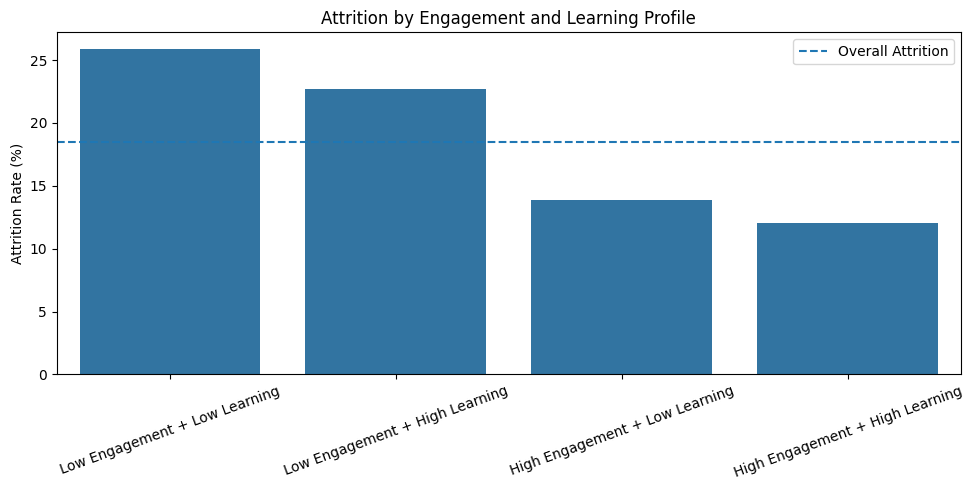

In [180]:
#Visualisation

plt.figure(figsize=(10, 5))

sns.barplot(
    data=interaction_analysis,
    x="Engagement_Learning_Profile",
    y="Attrition_Rate_Pct"
)

plt.axhline(
    overall_attrition,
    linestyle="--",
    label="Overall Attrition"
)

plt.title(
    "Attrition by Engagement and Learning Profile"
)

plt.xlabel("")
plt.ylabel("Attrition Rate (%)")

plt.xticks(
    rotation=20
)

plt.legend()

plt.tight_layout()
plt.show()

In [181]:
#7. Workforce Capacity & Sustainability Analysis

capacity_analysis = (
    analysis_df.groupby(
        "Financial_Year"
    )
    .agg(
        Employee_Headcount=(
            "Reported_Employee_Headcount",
            "first"
        ),
        Branch_Count=(
            "Reported_Branch_Count",
            "first"
        ),
        Reported_Turnover_Rate=(
            "Reported_Employee_Turnover_Rate_Pct",
            "first"
        )
    )
    .reset_index()
)


capacity_analysis[
    "Employees_Per_Branch"
] = (
    capacity_analysis[
        "Employee_Headcount"
    ]
    /
    capacity_analysis[
        "Branch_Count"
    ]
)


capacity_analysis[
    "Workforce_Growth_Pct"
] = (
    capacity_analysis[
        "Employee_Headcount"
    ]
    .pct_change()
    * 100
)


capacity_analysis[
    "Branch_Growth_Pct"
] = (
    capacity_analysis[
        "Branch_Count"
    ]
    .pct_change()
    * 100
)


capacity_analysis[
    "Workforce_vs_Branch_Growth_Gap"
] = (
    capacity_analysis[
        "Workforce_Growth_Pct"
    ]
    -
    capacity_analysis[
        "Branch_Growth_Pct"
    ]
)


display(
    capacity_analysis.round(2)
)

,Financial_Year,Employee_Headcount,Branch_Count,Reported_Turnover_Rate,Employees_Per_Branch,Workforce_Growth_Pct,Branch_Growth_Pct,Workforce_vs_Branch_Growth_Gap
0,FY2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FY2025,214521.0,NaN,22.6,NaN,NaN,NaN,NaN
2,FY2026,211178.0,9689.0,23.1,21.8,-1.56,NaN,NaN


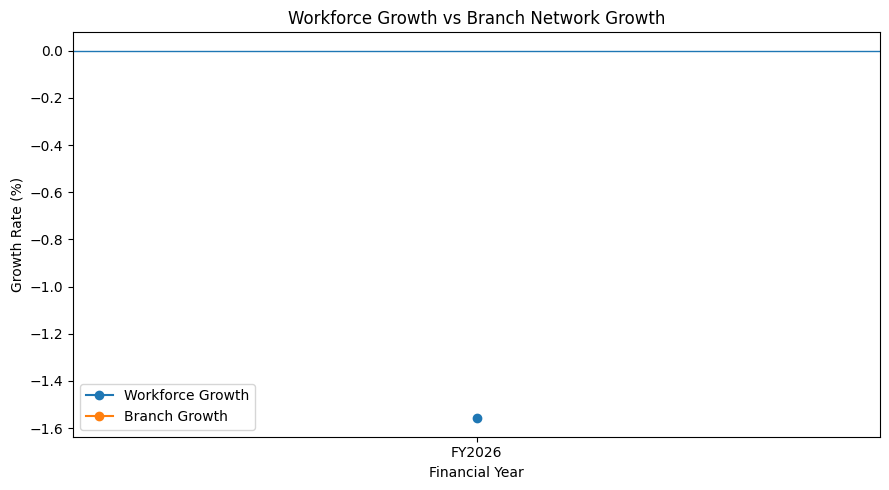

In [182]:
#Visualisation

plt.figure(figsize=(9, 5))

plt.plot(
    capacity_analysis["Financial_Year"],
    capacity_analysis["Workforce_Growth_Pct"],
    marker="o",
    label="Workforce Growth"
)

plt.plot(
    capacity_analysis["Financial_Year"],
    capacity_analysis["Branch_Growth_Pct"],
    marker="o",
    label="Branch Growth"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Workforce Growth vs Branch Network Growth"
)

plt.xlabel("Financial Year")
plt.ylabel("Growth Rate (%)")

plt.legend()

plt.tight_layout()
plt.show()

In [183]:
#8. Talent Pipeline & Retention Analysis

talent_variables = [
    col for col in [
        "Talent_Reviewed_Flag",
        "Internal_Hire_Flag"
    ]
    if col in analysis_df.columns
]


talent_retention_results = []


for variable in talent_variables:

    result = (
        analysis_df.groupby(
            variable
        )
        .agg(
            Employees=(
                "Employee_ID",
                "size"
            ),
            Exits=(
                "Employee_Exit_Flag",
                "sum"
            ),
            Attrition_Rate=(
                "Employee_Exit_Flag",
                "mean"
            ),
            Avg_Engagement=(
                "Engagement_Score_Synthetic",
                "mean"
            )
        )
        .reset_index()
    )

    result[
        "Attrition_Rate_Pct"
    ] = (
        result[
            "Attrition_Rate"
        ] * 100
    )

    result[
        "Analysis_Variable"
    ] = variable

    talent_retention_results.append(
        result
    )


for result in talent_retention_results:

    print(
        "\n",
        result[
            "Analysis_Variable"
        ].iloc[0]
    )

    display(
        result.round(2)
    )


 Talent_Reviewed_Flag


,Talent_Reviewed_Flag,Employees,Exits,Attrition_Rate,Avg_Engagement,Attrition_Rate_Pct,Analysis_Variable
0,0,29456,6255,0.21,75.74,21.24,Talent_Reviewed_Flag
1,1,7413,566,0.08,75.75,7.64,Talent_Reviewed_Flag



 Internal_Hire_Flag


,Internal_Hire_Flag,Employees,Exits,Attrition_Rate,Avg_Engagement,Attrition_Rate_Pct,Analysis_Variable
0,0,33553,6443,0.19,75.70,19.2,Internal_Hire_Flag
1,1,3316,378,0.11,76.16,11.4,Internal_Hire_Flag


In [184]:
#9. Consolidated Analytical Findings Table

print("=" * 75)
print("POST-EDA ANALYTICAL SUMMARY")
print("=" * 75)

print(
    "\nOverall Attrition Rate:",
    round(overall_attrition, 2),
    "%"
)


if not driver_results.empty:

    print(
        "\nStrongest categorical attrition association:",
        driver_results.iloc[0]["Factor"]
    )

    print(
        "Cramér's V:",
        round(
            driver_results.iloc[0][
                "Cramers_V"
            ],
            4
        )
    )


if not high_risk_cohorts.empty:

    print(
        "\nHighest-risk multi-dimensional cohort:"
    )

    display(
        high_risk_cohorts.head(1).round(2)
    )


print(
    "\nEngagement Analysis:"
)

display(
    engagement_attrition.round(2)
)


print(
    "\nEngagement × Learning Analysis:"
)

display(
    interaction_analysis.round(2)
)

POST-EDA ANALYTICAL SUMMARY

Overall Attrition Rate: 18.5 %

Strongest categorical attrition association: Age_Band_Clean
Cramér's V: 0.196

Highest-risk multi-dimensional cohort:


,Age_Band_Clean,Employee_Category,Region,Employee_Records,Exits,Attrition_Rate,Attrition_Rate_Pct,Attrition_Gap_Points
13,Under 30,Non-supervisory,South,2223,852,0.38,38.33,19.83



Engagement Analysis:


,Engagement_Quartile,Employees,Average_Engagement,Exits,Attrition_Rate,Attrition_Rate_Pct
0,Q1 - Lowest,9825,63.28,3176,0.32,32.33
1,Q2,9630,73.11,1387,0.14,14.40
2,Q3,9300,79.85,1203,0.13,12.94
3,Q4 - Highest,8114,89.24,1055,0.13,13.00



Engagement × Learning Analysis:


,Engagement_Learning_Profile,Employees,Exits,Attrition_Rate,Avg_Assessment_Improvement,Attrition_Rate_Pct,Attrition_Gap_Points
3,Low Engagement + Low Learning,9048,2344,0.26,14.55,25.91,7.41
2,Low Engagement + High Learning,8935,2028,0.23,14.38,22.70,4.20
1,High Engagement + Low Learning,9298,1291,0.14,14.53,13.88,-4.62
0,High Engagement + High Learning,9588,1158,0.12,14.30,12.08,-6.42


PREDICTIVE MODELLING

In [185]:
#Model-Specific Feature Selection

# ============================================================
# PART B: PREDICTIVE MODELLING
# TARGET: EMPLOYEE ATTRITION
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.tree import (
    DecisionTreeClassifier
)

from sklearn.ensemble import (
    RandomForestClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)


target = "Employee_Exit_Flag"


exclude_columns = [

    # Identifier
    "Employee_ID",

    # Target
    target,

    # Created during your EDA consistency check
    "Previous_Year_Exit",

    # Post-exit leakage
    "Exit_Reason_Synthetic",

    # Documentation
    "Data_Status",
    "Data_Provenance_Note",
    "RBI_Office_Data_Source",

    # Identifier
    "Branch_Assignment_ID",

    # Report-level information
    "Reported_Employee_Turnover_Rate_Pct",
    "Reported_Employee_Headcount",
    "Reported_Learning_Hours_Total",
    "Reported_Average_Learning_Hours_Per_Employee",
    "Reported_Training_Expense_INR_Crore",
    "Reported_Training_Expense_Per_Employee_INR",
    "Reported_Engagement_Vibes_Score",
    "Reported_Women_Workforce_Pct",
    "Reported_Employee_Expense_INR_Crore",
    "Reported_Branch_Count",

    # Aggregate network variables
    "Branch_Count_Synthetic_Year_Total",
    "Branches_Opened_Synthetic_Year_Total",
    "Region_Branch_Count_Synthetic",
    "Region_Branches_Opened_Synthetic",
    "RBI_HDFC_Office_Opening_Count"
]


exclude_columns = [
    col
    for col in exclude_columns
    if col in df.columns
]


X = df.drop(
    columns=exclude_columns
).copy()

y = df[target].copy()


print(
    "Observations:",
    X.shape[0]
)

print(
    "Predictors:",
    X.shape[1]
)

Observations: 36869
Predictors: 28


In [186]:
#Numerical/Categorical Features

categorical_features = (
    X.select_dtypes(
        include=[
            "object",
            "category",
            "bool"
        ]
    )
    .columns
    .tolist()
)


numerical_features = (
    X.select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)


print(
    "Numerical predictors:",
    len(numerical_features)
)

print(
    "Categorical predictors:",
    len(categorical_features)
)

Numerical predictors: 19
Categorical predictors: 9


In [187]:
#Train-Test Split

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)


print(
    "Training records:",
    len(X_train)
)

print(
    "Testing records:",
    len(X_test)
)

print(
    "Training attrition:",
    round(
        y_train.mean() * 100,
        2
    ),
    "%"
)

print(
    "Testing attrition:",
    round(
        y_test.mean() * 100,
        2
    ),
    "%"
)

Training records: 29495
Testing records: 7374
Training attrition: 18.5 %
Testing attrition: 18.5 %


In [188]:
#Model Preprocessing

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [189]:
#Logistic Regression

logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)


logistic_model.fit(
    X_train,
    y_train
)


log_pred = (
    logistic_model.predict(
        X_test
    )
)


log_prob = (
    logistic_model.predict_proba(
        X_test
    )[:, 1]
)


print(
    "LOGISTIC REGRESSION"
)

print(
    classification_report(
        y_test,
        log_pred,
        digits=4
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0     0.9380    0.7607    0.8401      6010
           1     0.4248    0.7786    0.5497      1364

    accuracy                         0.7640      7374
   macro avg     0.6814    0.7697    0.6949      7374
weighted avg     0.8431    0.7640    0.7864      7374



In [190]:
#Decision Tree

decision_tree_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=6,
                min_samples_leaf=30,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)


decision_tree_model.fit(
    X_train,
    y_train
)


dt_pred = (
    decision_tree_model.predict(
        X_test
    )
)


dt_prob = (
    decision_tree_model.predict_proba(
        X_test
    )[:, 1]
)


print(
    "DECISION TREE"
)

print(
    classification_report(
        y_test,
        dt_pred,
        digits=4
    )
)

DECISION TREE
              precision    recall  f1-score   support

           0     0.9746    0.9391    0.9565      6010
           1     0.7688    0.8922    0.8259      1364

    accuracy                         0.9304      7374
   macro avg     0.8717    0.9157    0.8912      7374
weighted avg     0.9365    0.9304    0.9324      7374



In [191]:
#Random Forest

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=10,
                min_samples_leaf=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


random_forest_model.fit(
    X_train,
    y_train
)


rf_pred = (
    random_forest_model.predict(
        X_test
    )
)


rf_prob = (
    random_forest_model.predict_proba(
        X_test
    )[:, 1]
)


print(
    "RANDOM FOREST"
)

print(
    classification_report(
        y_test,
        rf_pred,
        digits=4
    )
)

RANDOM FOREST
              precision    recall  f1-score   support

           0     0.9740    0.9394    0.9564      6010
           1     0.7692    0.8893    0.8249      1364

    accuracy                         0.9302      7374
   macro avg     0.8716    0.9144    0.8906      7374
weighted avg     0.9361    0.9302    0.9321      7374



In [196]:

import joblib

joblib.dump(
    random_forest_model,
    "random_forest_attrition_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [197]:

from google.colab import files

files.download("random_forest_attrition_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [192]:
#Model Comparison

model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(
            y_test,
            log_pred
        ),
        accuracy_score(
            y_test,
            dt_pred
        ),
        accuracy_score(
            y_test,
            rf_pred
        )
    ],

    "Precision": [
        precision_score(
            y_test,
            log_pred
        ),
        precision_score(
            y_test,
            dt_pred
        ),
        precision_score(
            y_test,
            rf_pred
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            log_pred
        ),
        recall_score(
            y_test,
            dt_pred
        ),
        recall_score(
            y_test,
            rf_pred
        )
    ],

    "F1_Score": [
        f1_score(
            y_test,
            log_pred
        ),
        f1_score(
            y_test,
            dt_pred
        ),
        f1_score(
            y_test,
            rf_pred
        )
    ],

    "ROC_AUC": [
        roc_auc_score(
            y_test,
            log_prob
        ),
        roc_auc_score(
            y_test,
            dt_prob
        ),
        roc_auc_score(
            y_test,
            rf_prob
        )
    ]
})


model_comparison = (
    model_comparison
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    model_comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Decision Tree,0.9304,0.7688,0.8922,0.8259,0.9513
1,Random Forest,0.9302,0.7692,0.8893,0.8249,0.9429
2,Logistic Regression,0.7640,0.4248,0.7786,0.5497,0.8448


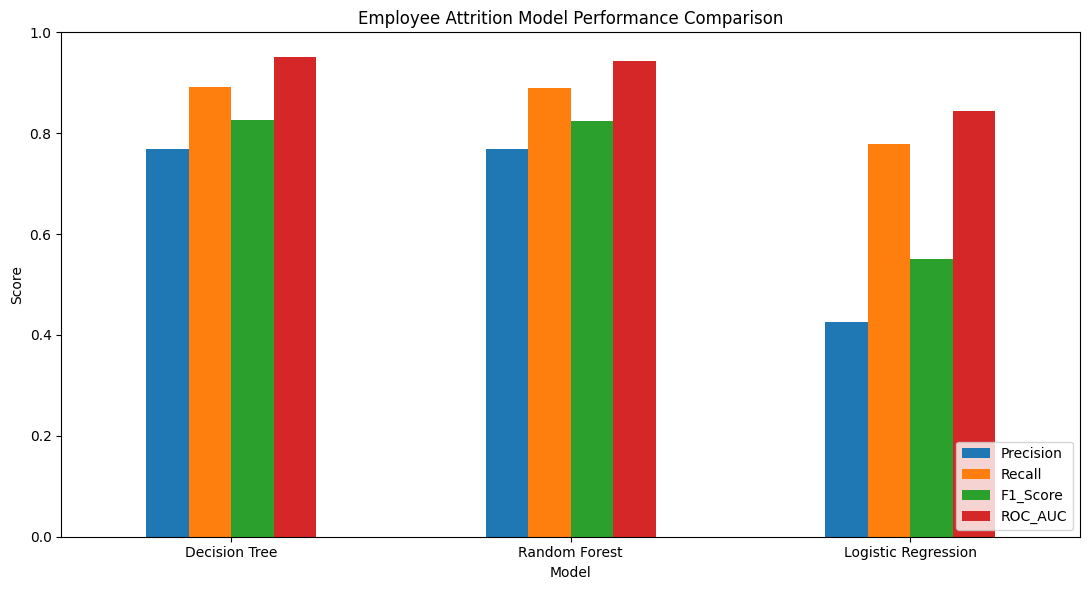

In [193]:
#Visual Model Comparison

comparison_plot = (
    model_comparison
    .set_index("Model")
    [
        [
            "Precision",
            "Recall",
            "F1_Score",
            "ROC_AUC"
        ]
    ]
)


comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)


plt.title(
    "Employee Attrition Model Performance Comparison"
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

plt.show()

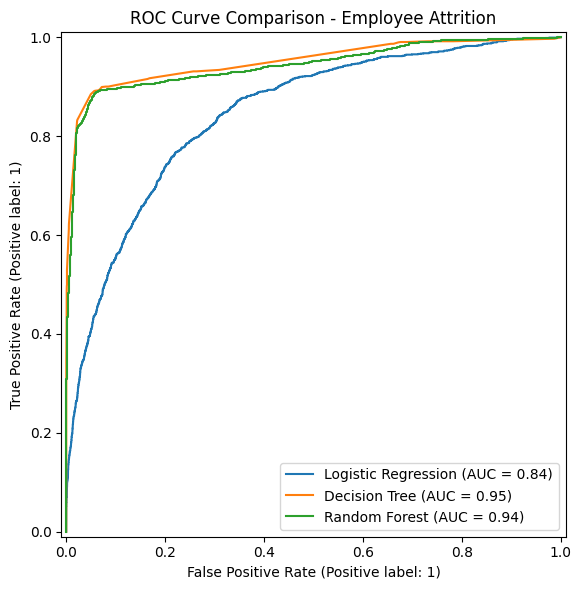

In [194]:
#ROC Curves

fig, ax = plt.subplots(
    figsize=(9, 6)
)


RocCurveDisplay.from_predictions(
    y_test,
    log_prob,
    name="Logistic Regression",
    ax=ax
)


RocCurveDisplay.from_predictions(
    y_test,
    dt_prob,
    name="Decision Tree",
    ax=ax
)


RocCurveDisplay.from_predictions(
    y_test,
    rf_prob,
    name="Random Forest",
    ax=ax
)


plt.title(
    "ROC Curve Comparison - Employee Attrition"
)

plt.tight_layout()

plt.show()

In [195]:
#Confusion Matrices

model_predictions = {
    "Logistic Regression": log_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}


for model_name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            "Actual Stay",
            "Actual Exit"
        ],
        columns=[
            "Predicted Stay",
            "Predicted Exit"
        ]
    )

    print(
        "\n",
        model_name
    )

    display(
        cm_df
    )


 Logistic Regression


,Predicted Stay,Predicted Exit
Actual Stay,4572,1438
Actual Exit,302,1062



 Decision Tree


,Predicted Stay,Predicted Exit
Actual Stay,5644,366
Actual Exit,147,1217



 Random Forest


,Predicted Stay,Predicted Exit
Actual Stay,5646,364
Actual Exit,151,1213
